# Análisis Exploratorio de Datos — Predict Future Sales

**Proyecto #1** · Maestría · 4T 2026 · Product Management · Clase Cloud
**Autor:** Danny García

---

Ventas diarias de la cadena de tiendas rusa **1C Company** entre enero de 2013 y octubre de
2015. El objetivo final de la competencia es predecir las ventas **mensuales** de cada par
tienda-producto para **noviembre de 2015** (mes 34). Este notebook prepara el terreno para esa
etapa de *forecasting*.

## Alcance y criterio de trabajo

Este notebook **diagnostica, no interviene**. Se identifican problemas de calidad, outliers y
registros inválidos, y se **define** la estrategia para tratarlos, pero no se elimina ni se
imputa nada: eso corresponde a la fase de limpieza. Separar el diagnóstico de la acción evita
decisiones tomadas de paso, sin discutirlas.

Cada gráfica lleva su métrica en el título, para poder ordenarlas y compararlas.

## Índice

| # | Sección |
|---|---|
| 0 | [Configuración](#0) |
| 1 | [Comprensión inicial del dataset](#1) |
| 2 | [Validación de la estructura de los datos](#2) |
| 3 | [Valores faltantes y duplicados](#3) |
| 4 | [Análisis descriptivo general](#4) |
| 5 | [Exploración temporal](#5) |
| 6 | [Análisis comparativo entre sucursales y productos](#6) |
| 7 | [Visualizaciones clave](#7) |
| 8 | [Autocorrelación (ACF) y autocorrelación parcial (PACF)](#8) |
| 9 | [Insights y conclusiones del EDA](#9) |

<a id="0"></a>
## 0. Configuración

Importaciones, rutas y ajustes de presentación.

Los catálogos de tiendas y productos están en **cirílico**, así que se verifica explícitamente
que la fuente tenga los glifos: si no los tiene, matplotlib dibuja rectángulos vacíos y las
etiquetas de los puntos 7.2 y 7.3 quedan ilegibles.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, pacf

from predict_future_sales.config import FIGURES_DIR, RAW_DATA_DIR

print("pandas", pd.__version__, "| numpy", np.__version__)

2026-11-12 22:54:08.244 -06:00 | INFO     | predict_future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales


pandas 3.1.1 | numpy 2.4.6


In [2]:
# Rutas: se toman del paquete del proyecto, no se escriben a mano en el notebook.
print("datos crudos:", RAW_DATA_DIR)
print("figuras     :", FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

datos crudos: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales\data\raw
figuras     : C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales\reports\figures


In [3]:
# ---------------------------------------------------------------------------
# Paleta y estilo
# ---------------------------------------------------------------------------
# Categoricos: se asignan SIEMPRE en este orden fijo, nunca ciclados, y el color
# sigue a la entidad, no a su posicion en el ranking. Con tres ranuras basta para
# todo lo que se grafica aqui.
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
ROJO = "#e34948"           # polo opuesto del divergente (variacion negativa)
TINTA, TINTA2 = "#0b0b0b", "#52514e"
REJILLA, EJE = "#e1e0d9", "#c3c2b7"

# Secuencial: un solo tono, claro -> oscuro. Nunca un arcoiris.
RAMPA_AZUL = LinearSegmentedColormap.from_list(
    "azul_seq",
    ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": EJE,
    "axes.labelcolor": TINTA2,
    "axes.titlecolor": TINTA,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": REJILLA,
    "grid.linewidth": 0.8,
    "xtick.color": TINTA2,
    "ytick.color": TINTA2,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.linewidth": 2,
    "lines.markersize": 5,
    "figure.dpi": 110,
    "savefig.bbox": "tight",
    "font.family": "DejaVu Sans",
})

def miles(x, _=None):
    """Formatea el eje en miles/millones, para no leer ceros."""
    if abs(x) >= 1e9:
        return f"{x / 1e9:,.1f} MM"
    if abs(x) >= 1e6:
        return f"{x / 1e6:,.1f} M"
    if abs(x) >= 1e3:
        return f"{x / 1e3:,.0f} k"
    return f"{x:,.0f}"

FMT = FuncFormatter(miles)

def guarda(fig, nombre):
    fig.savefig(FIGURES_DIR / f"{nombre}.png", dpi=150)

In [4]:
# Verificacion de glifos cirilicos: mirar el resultado, no suponerlo.
from matplotlib import font_manager
from matplotlib.ft2font import FT2Font

ruta = font_manager.findfont(font_manager.FontProperties(family=plt.rcParams["font.family"]))
mapa = FT2Font(ruta).get_charmap()
muestra = "Якутск Жуковский м²"
faltan = {c for c in muestra if c.strip() and ord(c) not in mapa}
print("fuente:", Path(ruta).name)
print("glifos faltantes para", repr(muestra), "->", faltan if faltan else "ninguno")
assert not faltan, "La fuente no cubre el cirilico: las etiquetas saldrian como rectangulos."

fuente: DejaVuSans.ttf
glifos faltantes para 'Якутск Жуковский м²' -> ninguno


<a id="1"></a>
## 1. Comprensión inicial del dataset

**Qué se responde aquí:** qué hay en cada archivo, de qué tamaño, qué significa cada columna,
cuál es la variable objetivo y qué periodo cubren los datos.

### 1.1 Carga de los archivos y primeras filas

In [5]:
sales = pd.read_csv(RAW_DATA_DIR / "sales_train.csv", encoding="utf-8")
items = pd.read_csv(RAW_DATA_DIR / "items.csv", encoding="utf-8")
cats = pd.read_csv(RAW_DATA_DIR / "item_categories.csv", encoding="utf-8")
shops = pd.read_csv(RAW_DATA_DIR / "shops.csv", encoding="utf-8")
test = pd.read_csv(RAW_DATA_DIR / "test.csv", encoding="utf-8")
submission = pd.read_csv(RAW_DATA_DIR / "sample_submission.csv", encoding="utf-8")

TABLAS = {
    "sales_train": sales,
    "test": test,
    "sample_submission": submission,
    "items": items,
    "item_categories": cats,
    "shops": shops,
}
print("6 archivos cargados")

6 archivos cargados


In [6]:
for nombre, df in TABLAS.items():
    print(f"\n{'=' * 70}\n{nombre}  —  {df.shape[0]:,} filas x {df.shape[1]} columnas\n{'=' * 70}")
    display(df.head(3))


sales_train  —  2,935,849 filas x 6 columnas


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00



test  —  214,200 filas x 3 columnas


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233



sample_submission  —  214,200 filas x 2 columnas


,ID,item_cnt_month
0,0,0.50
1,1,0.50
2,2,0.50


... (2 outputs left out)


item_categories  —  84 filas x 2 columnas


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2



shops  —  60 filas x 2 columnas


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2


La descarga de Kaggle trae **6 archivos, no 5**: el enunciado no menciona `sample_submission.csv`.
Se conserva porque confirma el nombre oficial de la variable objetivo (`item_cnt_month`) y las
filas exactas a predecir.

### 1.2 Tamaño de cada tabla

In [7]:
resumen = pd.DataFrame(
    [(n, d.shape[0], d.shape[1], ", ".join(d.columns)) for n, d in TABLAS.items()],
    columns=["tabla", "filas", "columnas", "nombres de columna"],
).set_index("tabla")
display(resumen)
print("peso en disco de los archivos crudos:")
for f in sorted(RAW_DATA_DIR.glob("*.csv")):
    print(f"  {f.name:<24} {f.stat().st_size / 1e6:>7.1f} MB")

,filas,columnas,nombres de columna
tabla,,,
sales_train,2935849,6,"date, date_block_num, shop_id, item_id, item_p..."
test,214200,3,"ID, shop_id, item_id"
sample_submission,214200,2,"ID, item_cnt_month"
items,22170,3,"item_name, item_id, item_category_id"
item_categories,84,2,"item_category_name, item_category_id"
shops,60,2,"shop_name, shop_id"


peso en disco de los archivos crudos:
  item_categories.csv          0.0 MB
  items.csv                    1.6 MB
  sales_train.csv             94.6 MB
  sample_submission.csv        2.2 MB
  shops.csv                    0.0 MB
  test.csv                     3.2 MB


### 1.3 Descripción de las columnas y variable objetivo

| Columna | Tabla | Qué representa |
|---|---|---|
| `date` | `sales_train` | Fecha de la transacción. Viene como **texto** en formato `dd.mm.aaaa` |
| `date_block_num` | `sales_train` | Número de mes consecutivo: 0 = enero 2013 … 33 = octubre 2015 |
| `shop_id` | `sales_train`, `test`, `shops` | Identificador de la tienda (sucursal) |
| `item_id` | `sales_train`, `test`, `items` | Identificador del producto |
| `item_price` | `sales_train` | Precio unitario del producto ese día en esa tienda, en rublos |
| `item_cnt_day` | `sales_train` | Unidades vendidas ese día. **Negativo = devolución** |
| `item_name` | `items` | Nombre del producto (cirílico) |
| `item_category_id` | `items`, `item_categories` | Identificador de la categoría del producto |
| `item_category_name` | `item_categories` | Nombre de la categoría (cirílico) |
| `shop_name` | `shops` | Nombre de la tienda: ciudad + centro comercial (cirílico) |
| `ID` | `test`, `sample_submission` | Identificador de la fila a predecir |
| `item_cnt_month` | `sample_submission` | **La variable objetivo** |

#### La variable objetivo no existe en los datos: hay que construirla

`sales_train` tiene **transacciones diarias**; lo que se predice son **unidades mensuales por
par tienda-producto**:

$$\text{item\_cnt\_month}(s, i, m) = \sum_{d \in m} \text{item\_cnt\_day}(s, i, d)$$

Tampoco existe una columna de dinero. Se construye como `item_price × item_cnt_day` (sección 4.1)
y es una variable **auxiliar**: sirve para entender el negocio y ponderar la importancia de
tiendas y productos, pero no es lo que se predice.

### 1.4 Rango temporal y número de meses cubiertos

In [8]:
fechas = pd.to_datetime(sales["date"], format="%d.%m.%Y")
print(f"fecha minima : {fechas.min():%Y-%m-%d}")
print(f"fecha maxima : {fechas.max():%Y-%m-%d}")
print(f"dias calendario en el rango : {(fechas.max() - fechas.min()).days + 1:,}")
print(f"meses cubiertos (date_block_num) : {sales.date_block_num.nunique()} "
      f"({sales.date_block_num.min()} a {sales.date_block_num.max()})")
print(f"\nmes a predecir: 34 = noviembre 2015 (el mes siguiente al ultimo observado)")

fecha minima : 2013-01-01
fecha maxima : 2015-10-31
dias calendario en el rango : 1,034
meses cubiertos (date_block_num) : 34 (0 a 33)

mes a predecir: 34 = noviembre 2015 (el mes siguiente al ultimo observado)


<a id="2"></a>
## 2. Validación de la estructura de los datos

**Qué se responde aquí:** si los tipos son correctos, si `date` quedó bien convertida, si
`date_block_num` es consistente con la fecha, si hay días sin ventas y a qué frecuencia conviene
agregar.

### 2.1 Tipos de datos por variable

In [9]:
tipos = pd.DataFrame({
    "dtype_original": sales.dtypes.astype(str),
    "n_unicos": sales.nunique(),
})
tipos["rol"] = [
    "temporal (texto -> datetime)", "temporal (entero ordinal)",
    "categorica (identificador)", "categorica (identificador)",
    "numerica continua", "numerica discreta (objetivo diario)",
]
display(tipos)

,dtype_original,n_unicos,rol
date,str,1034,temporal (texto -> datetime)
date_block_num,int64,34,temporal (entero ordinal)
shop_id,int64,60,categorica (identificador)
item_id,int64,21807,categorica (identificador)
item_price,float64,19993,numerica continua
item_cnt_day,float64,198,numerica discreta (objetivo diario)


`shop_id` e `item_id` son **enteros, pero no son números**: son identificadores categóricos. Su
magnitud no significa nada —la tienda 59 no es "más" que la tienda 2— y promediarlos o
escalarlos sería un error. Esto descarta de entrada la caja de herramientas habitual de
correlación numérica.

### 2.2 Conversión de `date` a datetime

In [10]:
sales["date"] = pd.to_datetime(sales["date"], format="%d.%m.%Y")
assert sales["date"].notna().all(), "Hay fechas que no se pudieron convertir"
assert str(sales["date"].dtype).startswith("datetime64"), "date no quedo como datetime"
print("date ->", sales["date"].dtype)
display(sales.dtypes.to_frame("dtype"))

date -> datetime64[us]


,dtype
date,datetime64[us]
date_block_num,int64
shop_id,int64
item_id,int64
item_price,float64
item_cnt_day,float64


### 2.3 Frecuencia temporal: días sin ventas y consistencia de `date_block_num`

In [11]:
calendario = pd.date_range(sales.date.min(), sales.date.max(), freq="D")
con_venta = sales.date.unique()
sin_venta = calendario.difference(pd.DatetimeIndex(con_venta))

print(f"dias del calendario           : {len(calendario):,}")
print(f"dias con al menos una venta   : {len(con_venta):,}")
print(f"dias SIN ninguna venta        : {len(sin_venta)}")

dias del calendario           : 1,034
dias con al menos una venta   : 1,034
dias SIN ninguna venta        : 0


In [12]:
# date_block_num deberia ser el numero de mes consecutivo desde enero de 2013.
bloque_calculado = (sales.date.dt.year - 2013) * 12 + (sales.date.dt.month - 1)
inconsistentes = int((bloque_calculado != sales.date_block_num).sum())
print(f"filas donde date_block_num NO coincide con la fecha: {inconsistentes:,} "
      f"de {len(sales):,}")
assert inconsistentes == 0

filas donde date_block_num NO coincide con la fecha: 0 de 2,935,849


In [13]:
# A nivel diario la serie total esta completa, pero ¿que pasa con el grano que
# importa, el par tienda-producto?
pares_obs = sales.groupby(["shop_id", "item_id"], observed=True).size()
celdas_con_venta = len(sales.groupby(["date_block_num", "shop_id", "item_id"], observed=True).size())
rejilla_completa = sales.shop_id.nunique() * sales.item_id.nunique() * sales.date_block_num.nunique()

print(f"pares tienda-producto observados      : {len(pares_obs):,}")
print(f"celdas (mes, tienda, producto) con venta : {celdas_con_venta:,}")
print(f"rejilla mensual completa                 : {rejilla_completa:,}")
print(f"densidad de la rejilla                   : {celdas_con_venta / rejilla_completa:.3%}")

meses_por_par = sales.groupby(["shop_id", "item_id"], observed=True).date_block_num.nunique()
print(f"\npares con UN solo mes de historial     : {(meses_por_par == 1).sum():,} "
      f"({(meses_por_par == 1).mean():.1%})")
print(f"pares con los 34 meses                   : {(meses_por_par == 34).sum():,}")
print(f"mediana de meses de historial por par    : {meses_por_par.median():.0f}")

pares tienda-producto observados      : 424,124
celdas (mes, tienda, producto) con venta : 1,609,124
rejilla mensual completa                 : 44,486,280
densidad de la rejilla                   : 3.617%



pares con UN solo mes de historial     : 146,631 (34.6%)
pares con los 34 meses                   : 102
mediana de meses de historial por par    : 2


### 2.4 Conclusión sobre la frecuencia de agregación

**Conviene agregar a nivel mensual.** Tres razones medidas, no de preferencia:

1. **Es la frecuencia del problema.** La competencia pide `item_cnt_month`. Cualquier otra
   agregación exige un paso de conversión adicional, con su propio riesgo de error.
2. **A nivel diario la señal del par tienda-producto es casi toda ceros.** La rejilla mensual
   completa ya está vacía en un **96.4 %**; la diaria lo estaría 30 veces más. Modelar una serie
   de ceros con picos aislados es un problema distinto —y mucho peor planteado— que modelar
   conteos mensuales.
3. **Pero la señal diaria no es ruido.** La serie *total* diaria está completa (0 días sin
   ventas) y, como se ve en la sección 8, tiene un ciclo semanal fortísimo. Esa estructura es
   útil como variable derivada (número de fines de semana del mes, días hábiles), no como grano
   de modelado.

**Decisión:** modelar a nivel mensual; explorar lo diario solo para la serie agregada y para
construir variables de calendario.

<a id="3"></a>
## 3. Análisis de valores faltantes y duplicados

**Qué se responde aquí:** qué falta, qué es inválido sin ser nulo, qué está duplicado y qué se
va a hacer con cada caso.

### 3.1 Valores nulos y porcentaje de datos faltantes

In [14]:
filas = []
for nombre, df in TABLAS.items():
    n = df.isna().sum()
    filas.append({
        "tabla": nombre,
        "celdas": df.size,
        "nulos": int(n.sum()),
        "% nulos": n.sum() / df.size * 100,
        "columnas con nulos": ", ".join(n[n > 0].index) or "—",
    })
display(pd.DataFrame(filas).set_index("tabla"))

,celdas,nulos,% nulos,columnas con nulos
tabla,,,,
sales_train,17615094,0,0.00,—
test,642600,0,0.00,—
sample_submission,428400,0,0.00,—
items,66510,0,0.00,—
item_categories,168,0,0.00,—
shops,120,0,0.00,—


**Cero nulos en las seis tablas.** No hay nada que imputar, así que toda la maquinaria habitual
—reglas por porcentaje, faltantes estructurales contra reales, indicadores de ausencia— **no
aplica aquí**. El problema de calidad de este dataset no es de *ausencia*, es de **validez**: hay
valores presentes que no pueden ser ciertos. Eso es lo que se revisa a continuación.

### 3.2 Valores inválidos que no son nulos

In [15]:
sales["ingresos"] = sales["item_price"] * sales["item_cnt_day"]

precio_malo = sales[sales.item_price <= 0]
print(f"filas con item_price <= 0: {len(precio_malo)}")
display(precio_malo)

filas con item_price <= 0: 1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,ingresos
484683,2013-05-15,4,32,2973,-1.00,1.00,-1.00


In [16]:
devoluciones = sales[sales.item_cnt_day < 0]
print(f"filas con item_cnt_day < 0 : {len(devoluciones):,} ({len(devoluciones) / len(sales):.3%})")
print(f"filas con item_cnt_day == 0: {(sales.item_cnt_day == 0).sum()}")
print(f"unidades devueltas         : {devoluciones.item_cnt_day.sum():,.0f}")
print(f"importe devuelto           : {devoluciones.ingresos.sum():,.0f} rublos "
      f"({abs(devoluciones.ingresos.sum()) / sales.ingresos.sum():.2%} de los ingresos)")
print(f"meses en que ocurren       : {devoluciones.date_block_num.nunique()} de 34")
print(f"tiendas afectadas          : {devoluciones.shop_id.nunique()} de {sales.shop_id.nunique()}")

filas con item_cnt_day < 0 : 7,356 (0.251%)
filas con item_cnt_day == 0: 0
unidades devueltas         : -7,541
importe devuelto           : -10,929,688 rublos (0.32% de los ingresos)
meses en que ocurren       : 34 de 34
tiendas afectadas          : 54 de 60


Las dos anomalías son de naturaleza **opuesta**, y por eso no se tratan igual:

- **El precio negativo es un error.** Un solo registro en 2.9 millones (`shop_id` 32,
  `item_id` 2973, 15-05-2013). No hay interpretación de negocio posible para un precio de −1.
- **Las cantidades negativas no son un error.** Son 7 356 devoluciones, repartidas en **los 34
  meses** y en casi todas las tiendas: no es un episodio aislado, es cómo opera el negocio. Pesan
  el 0.32 % de los ingresos. Borrarlas inflaría las ventas netas.

### 3.3 Registros duplicados

In [17]:
dups = sales[sales.duplicated(keep=False)].sort_values(list(sales.columns[:4]))
print(f"filas duplicadas exactas: {len(dups)} ({dups.duplicated().sum()} sobrantes)")
display(dups)

filas duplicadas exactas: 12 (6 sobrantes)


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,ingresos
76961,2013-01-05,0,54,20130,149.00,1.00,149.00
76962,2013-01-05,0,54,20130,149.00,1.00,149.00
1435365,2014-02-23,13,50,3423,999.00,1.00,999.00
1435367,2014-02-23,13,50,3423,999.00,1.00,999.00
1496765,2014-03-23,14,21,3423,999.00,1.00,999.00
1496766,2014-03-23,14,21,3423,999.00,1.00,999.00
1671872,2014-05-01,16,50,3423,999.00,1.00,999.00
1671873,2014-05-01,16,50,3423,999.00,1.00,999.00
1866322,2014-07-12,18,25,3423,999.00,1.00,999.00
1866340,2014-07-12,18,25,3423,999.00,1.00,999.00


Doce filas forman seis pares idénticos. **No se puede distinguir** un error de carga de dos
clientes que compraron el mismo producto el mismo día en la misma tienda al mismo precio —que es
un suceso perfectamente normal en una tienda. Cuatro de los seis pares son el mismo `item_id`
3423, lo que inclina la balanza hacia un problema de carga, pero no lo prueba.

Pesan 6 filas sobre 2 935 849: **0.0002 %**. Cualquiera de las dos decisiones es irrelevante para
el resultado.

### 3.4 Tiendas repetidas en `shops.csv`

In [18]:
# La comparacion exacta de nombres no encuentra nada: hay que normalizar.
shops["nombre_norm"] = (
    shops.shop_name.str.strip().str.lower()
    .str.replace(r"^!", "", regex=True)
    .str.replace(r'["\u00ab\u00bb]', "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
)
exactos = shops[shops.shop_name.duplicated(keep=False)]
normalizados = shops[shops.nombre_norm.duplicated(keep=False)]
print(f"tiendas con nombre EXACTAMENTE igual : {len(exactos)}")
print(f"tiendas con nombre normalizado igual : {len(normalizados)}")

tiendas con nombre EXACTAMENTE igual : 0
tiendas con nombre normalizado igual : 0


In [19]:
# Pares candidatos detectados por prefijo comun largo, mas su ventana de actividad.
actividad = sales.groupby("shop_id").agg(
    primer_mes=("date_block_num", "min"),
    ultimo_mes=("date_block_num", "max"),
    meses_activos=("date_block_num", "nunique"),
    transacciones=("item_cnt_day", "size"),
)
panorama = shops.set_index("shop_id").join(actividad)
panorama["en_test"] = panorama.index.isin(test.shop_id)

CANDIDATOS = [(0, 57), (1, 58), (10, 11), (39, 40)]
for a, b in CANDIDATOS:
    display(panorama.loc[[a, b], ["shop_name", "primer_mes", "ultimo_mes",
                                  "meses_activos", "transacciones", "en_test"]])

,shop_name,primer_mes,ultimo_mes,meses_activos,transacciones,en_test
shop_id,,,,,,
0,"!Якутск Орджоникидзе, 56 фран",0,1,2,9857,False
57,"Якутск Орджоникидзе, 56",2,33,32,117428,True


,shop_name,primer_mes,ultimo_mes,meses_activos,transacciones,en_test
shop_id,,,,,,
1,"!Якутск ТЦ ""Центральный"" фран",0,1,2,5678,False
58,"Якутск ТЦ ""Центральный""",2,33,32,71441,True


,shop_name,primer_mes,ultimo_mes,meses_activos,transacciones,en_test
shop_id,,,,,,
10,Жуковский ул. Чкалова 39м?,0,33,33,21397,True
11,Жуковский ул. Чкалова 39м²,25,25,1,499,False


,shop_name,primer_mes,ultimo_mes,meses_activos,transacciones,en_test
shop_id,,,,,,
39,"РостовНаДону ТРК ""Мегацентр Горизонт""",14,33,20,13440,True
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",14,24,11,4257,False


El punto 4c del enunciado pide buscar "mismo nombre con distinto ID". **Con comparación exacta el
resultado es cero**: no hay un solo nombre repetido. Hay que normalizar, y aun así la coincidencia
no es literal — son variantes del mismo local.

El patrón que los delata no está en el texto, está en el **tiempo**:

| Par | Qué pasa | Lectura |
|---|---|---|
| 0 / 57 | la 0 registra solo los meses 0–1; la 57 arranca en el 2 y llega al 33 | la misma tienda, re-registrada tras dejar de ser franquicia (`фран`) |
| 1 / 58 | idéntico patrón | misma lectura |
| 10 / 11 | la 11 existe **un solo mes** (25); la 10 cubre 0–33 | `м?` contra `м²`: un **fallo de codificación** partió el local en dos |
| 39 / 40 | la 40 va del 14 al 24; la 39 del 14 al 33 | sucursal que absorbe a la otra (`Островной`) |

En cada par, una tienda deja de registrar casi exactamente cuando la otra empieza, y **solo una
de las dos sobrevive en `test`**.

> **`shop_id` no es una identidad estable de sucursal.** Comparar el desempeño entre tiendas
> (sección 6.2) sin consolidar estos pares produce ocho series truncadas artificialmente: la 0 y
> la 1 parecerían tiendas fracasadas que cerraron a los dos meses, cuando en realidad siguen
> operando con otro número.

### 3.5 Estrategia de tratamiento

Se **define** aquí; se **ejecuta** en la fase de limpieza.

| Hallazgo | Volumen | Decisión | Razón |
|---|---|---|---|
| Valores nulos | 0 | Nada que hacer | No hay |
| `item_price <= 0` | 1 fila | **Imputar** con la mediana del mismo `item_id` en el mismo mes | Es un error inequívoco, pero descartar la fila también descarta una venta real |
| `item_cnt_day < 0` | 7 356 filas | **Conservar** | Son devoluciones reales, presentes en los 34 meses. Al agregar a mes se netean solas, que es el comportamiento correcto |
| Duplicados exactos | 6 filas | **Conservar** | No se puede distinguir error de carga de dos compras idénticas; pesan 0.0002 % |
| Tiendas duplicadas | 4 pares | **Consolidar** bajo el ID que sobrevive en test (57, 58, 10, 39) | Son el mismo local; sin consolidar, 8 series quedan truncadas |
| Outliers de precio y cantidad | ver 6.3 | **Conservar y documentar** | Se deciden uno por uno en 6.3, no por umbral |

**Lo que no se hace y por qué.** No se recorta por percentiles (winsorizado): en este dataset las
colas son el hallazgo —una consola de 308 000 rublos, una venta de 2 169 unidades— y recortarlas
borraría justo lo que hay que entender. No se transforma la variable objetivo con logaritmo:
`item_cnt_day` tiene ceros y valores negativos, donde el logaritmo no está definido.

<a id="4"></a>
## 4. Análisis descriptivo general

**Qué se responde aquí:** cómo se distribuyen precio, cantidad e ingresos, y cómo se reparten las
ventas entre productos, categorías, tiendas y periodos.

### 4.1 Construcción de la columna de ingresos

In [20]:
# Ya calculada en 3.2 para poder cuantificar las devoluciones; se verifica.
assert "ingresos" in sales.columns
assert np.allclose(sales.ingresos, sales.item_price * sales.item_cnt_day)
print(f"ingresos totales : {sales.ingresos.sum():,.0f} rublos")
print(f"unidades totales : {sales.item_cnt_day.sum():,.0f}")
print(f"ticket medio     : {sales.ingresos.sum() / sales.item_cnt_day.sum():,.2f} rublos/unidad")

ingresos totales : 3,398,926,345 rublos
unidades totales : 3,648,206
ticket medio     : 931.67 rublos/unidad


### 4.2 Métricas estadísticas básicas

In [21]:
desc = sales[["item_price", "item_cnt_day", "ingresos"]].describe().T
desc = desc.rename(columns={"50%": "mediana", "std": "desv_est"})
desc["mediana/media"] = desc["mediana"] / desc["mean"]
display(desc[["count", "mean", "mediana", "min", "max", "desv_est", "mediana/media"]])

print("\npercentiles:")
display(sales[["item_price", "item_cnt_day", "ingresos"]]
        .quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]))
print(f"\n% de transacciones de exactamente 1 unidad: {(sales.item_cnt_day == 1).mean():.1%}")

,count,mean,mediana,min,max,desv_est,mediana/media
item_price,"2,935,849.00",890.85,399.00,-1.00,"307,980.00","1,729.80",0.45
item_cnt_day,"2,935,849.00",1.24,1.00,-22.00,"2,169.00",2.62,0.80
ingresos,"2,935,849.00","1,157.73",449.00,"-68,970.00","1,829,990.00","5,683.60",0.39



percentiles:


,item_price,item_cnt_day,ingresos
0.01,5.00,1.00,18.00
0.25,249.00,1.00,249.00
0.50,399.00,1.00,449.00
0.75,999.00,1.00,"1,078.20"
0.95,"2,690.00",2.00,"3,196.00"
0.99,"5,999.00",5.00,"11,375.00"
1.00,"23,990.00",22.00,"45,487.15"



% de transacciones de exactamente 1 unidad: 89.6%


Las tres variables están **brutalmente sesgadas a la derecha**, y el tipo de sesgo es distinto en
cada una:

- **`item_cnt_day`** no es una variable continua: el **89.6 %** de las transacciones es
  exactamente **1 unidad**, y el percentil 99 es 5. La media (1.24) y la desviación (2.62)
  describen mal algo que es casi una constante con una cola larguísima: el máximo es **2 169**,
  414 desviaciones por encima de la media.
- **`item_price`** va de 5 rublos (p1) a 307 980 (máximo), con mediana 399. La media (891) es
  2.2 veces la mediana.
- **`ingresos`** heredan ambas colas y las multiplican: mediana 449, máximo 1 829 990.

**Consecuencia práctica:** cualquier métrica basada en la media sobre estos datos sin agregar
está dominada por unas pocas filas. Las comparaciones de las secciones 6 y 7 se hacen sobre
**sumas agregadas**, no sobre promedios de transacción.

### 4.3 Distribución de ventas por producto y por categoría

In [22]:
catalogo = items.merge(cats, on="item_category_id")
ventas = sales.merge(catalogo, on="item_id", how="left")
assert ventas.item_category_id.notna().all(), "Hay items sin categoria en el catalogo"

por_producto = ventas.groupby("item_id").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum")
).sort_values("unidades", ascending=False)

print(f"productos del catalogo            : {len(items):,}")
print(f"productos con alguna venta        : {len(por_producto):,}")
print(f"productos NUNCA vendidos          : {len(items) - len(por_producto):,}")
print(f"productos con <= 1 unidad vendida : {(por_producto.unidades <= 1).sum():,}")

productos del catalogo            : 22,170
productos con alguna venta        : 21,807
productos NUNCA vendidos          : 363
productos con <= 1 unidad vendida : 2,327


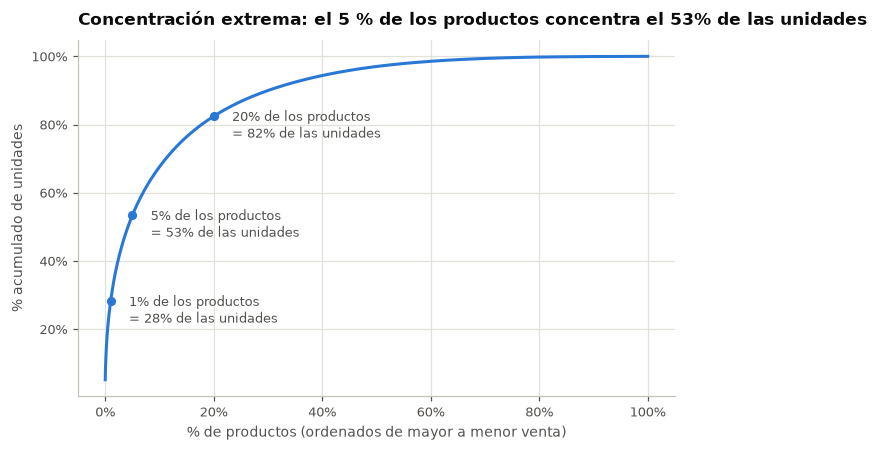

In [23]:
# Concentracion: que fraccion de los productos explica que fraccion de las unidades.
u = por_producto.unidades.clip(lower=0).sort_values(ascending=False)
acum = u.cumsum() / u.sum()
frac_prod = np.arange(1, len(u) + 1) / len(u)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(frac_prod * 100, acum * 100, color=AZUL)
for marca in (0.01, 0.05, 0.20):
    y = acum.iloc[int(len(u) * marca) - 1] * 100
    ax.plot([marca * 100], [y], "o", color=AZUL, zorder=3)
    ax.annotate(f"{marca:.0%} de los productos\n= {y:.0f}% de las unidades",
                (marca * 100, y), textcoords="offset points", xytext=(12, -14),
                fontsize=8.5, color=TINTA2)
ax.set_xlabel("% de productos (ordenados de mayor a menor venta)")
ax.set_ylabel("% acumulado de unidades")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title("Concentración extrema: el 5 % de los productos concentra el "
             f"{acum.iloc[int(len(u) * 0.05) - 1]:.0%} de las unidades")
guarda(fig, "4-3_concentracion_productos")
plt.show()

In [24]:
por_categoria = ventas.groupby(["item_category_id", "item_category_name"]).agg(
    unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum"),
    productos=("item_id", "nunique"),
).sort_values("unidades", ascending=False)

print(f"categorias con venta: {len(por_categoria)} de {len(cats)}")
print(f"las 10 primeras concentran "
      f"{por_categoria.head(10).unidades.sum() / por_categoria.unidades.sum():.1%} de las unidades")
display(por_categoria.head(10))
display(por_categoria.tail(5))

categorias con venta: 84 de 84
las 10 primeras concentran 72.1% de las unidades


,,unidades,ingresos,productos
item_category_id,item_category_name,,,
40,Кино - DVD,"634,171.00","169,944,221.69",4964
30,Игры PC - Стандартные издания,"456,540.00","257,519,291.08",751
55,Музыка - CD локального производства,"348,591.00","100,022,563.57",2327
19,Игры - PS3,"254,887.00","412,050,280.90",625
37,Кино - Blu-Ray,"203,284.00","90,478,731.84",1777
71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998.00","934,206.61",6
28,Игры PC - Дополнительные издания,"174,954.00","136,419,148.64",235
23,Игры - XBOX 360,"169,944.00","259,619,128.35",496
20,Игры - PS4,"127,319.00","373,010,312.01",157


,,unidades,ingresos,productos
item_category_id,item_category_name,,,
50,Книги - Открытки,3.00,58.00,2
53,Книги - Художественная литература,3.00,847.00,3
1,Аксессуары - PS2,2.00,431.00,2
10,Игровые консоли - PS2,1.00,"1,998.00",1
51,Книги - Познавательная литература,1.00,129.00,1


La distribución por producto es de **ley de potencias**: el 5 % de los productos concentra la
gran mayoría de las unidades, mientras **2 327 productos vendieron una unidad o menos en tres
años** y **363 no se vendieron nunca**. Por categoría la concentración es igual de marcada: las
10 primeras de 84 acumulan el **72.1 %** de las unidades.

Esto tiene una consecuencia directa para el *forecasting*: **la mayoría de las series
tienda-producto son casi todo ceros**. El modelo no se enfrenta a 21 807 series de demanda, sino
a unos cientos con señal y a decenas de miles de series intermitentes.

### 4.4 Distribución de ventas por sucursal

In [25]:
por_tienda = ventas.groupby("shop_id").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum"),
    meses=("date_block_num", "nunique"), transacciones=("item_cnt_day", "size"),
).join(shops.set_index("shop_id")[["shop_name"]])
por_tienda["en_test"] = por_tienda.index.isin(test.shop_id)
por_tienda["ingreso_medio_mes"] = por_tienda.ingresos / por_tienda.meses

print(f"tiendas con venta: {len(por_tienda)} de {len(shops)}")
print(f"las 10 primeras concentran "
      f"{por_tienda.nlargest(10, 'ingresos').ingresos.sum() / por_tienda.ingresos.sum():.1%} "
      f"de los ingresos")
print(f"razon entre la mayor y la menor (ingresos): "
      f"{por_tienda.ingresos.max() / por_tienda.ingresos.min():,.0f}x")
display(por_tienda.nlargest(5, "ingresos")[["shop_name", "unidades", "ingresos", "meses", "en_test"]])
display(por_tienda.nsmallest(5, "ingresos")[["shop_name", "unidades", "ingresos", "meses", "en_test"]])

tiendas con venta: 60 de 60
las 10 primeras concentran 42.7% de los ingresos
razon entre la mayor y la menor (ingresos): 623x


,shop_name,unidades,ingresos,meses,en_test
shop_id,,,,,
31,"Москва ТЦ ""Семеновский""","310,777.00","235,217,019.05",34,True
25,"Москва ТРК ""Атриум""","241,920.00","216,480,571.44",34,True
28,"Москва ТЦ ""МЕГА Теплый Стан"" II","184,557.00","159,746,337.38",34,True
42,"СПб ТК ""Невский Центр""","144,934.00","151,917,032.55",34,True
54,"Химки ТЦ ""Мега""","185,790.00","141,939,673.00",28,False


,shop_name,unidades,ingresos,meses,en_test
shop_id,,,,,
36,"Новосибирск ТРЦ ""Галерея Новосибирск""",330.00,"377,714.00",1,True
11,Жуковский ул. Чкалова 39м²,572.00,"521,655.14",1,False
8,"Воронеж ТРЦ Сити-Парк ""Град""","3,595.00","2,349,358.00",4,False
1,"!Якутск ТЦ ""Центральный"" фран","6,311.00","3,238,207.00",2,False
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной","4,943.00","4,293,586.85",11,False


### 4.5 Distribución de ventas por periodo (día, semana, mes, año)

In [26]:
sales["anio"] = sales.date.dt.year
sales["mes_anio"] = sales.date.dt.month
sales["dia_semana"] = sales.date.dt.day_of_week
sales["semana_iso"] = sales.date.dt.isocalendar().week.astype(int)

por_dia = sales.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum"))
por_mes = sales.groupby("date_block_num").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum"),
    transacciones=("item_cnt_day", "size"), tiendas=("shop_id", "nunique"),
    productos=("item_id", "nunique"),
)
por_mes["periodo"] = pd.PeriodIndex(
    [pd.Period(year=2013 + m // 12, month=m % 12 + 1, freq="M") for m in por_mes.index], freq="M"
)
por_anio = sales.groupby("anio").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum"),
    meses=("date_block_num", "nunique"),
)
por_anio["unidades_por_mes"] = por_anio.unidades / por_anio.meses
display(por_anio)

,unidades,ingresos,meses,unidades_por_mes
anio,,,,
2013,"1,562,733.00","1,217,524,733.98",12,"130,227.75"
2014,"1,320,889.00","1,346,778,478.81",12,"110,074.08"
2015,"764,584.00","834,623,131.78",10,"76,458.40"


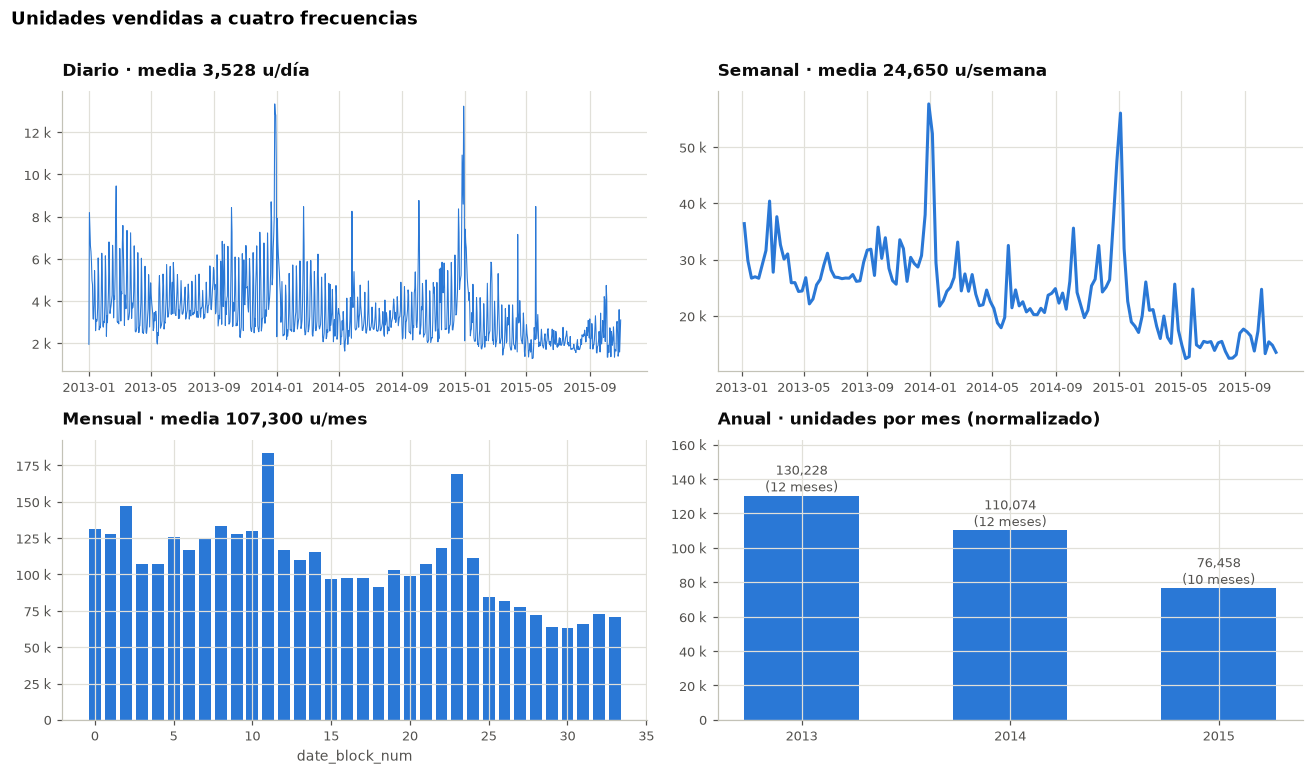

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

ax = axes[0, 0]
ax.plot(por_dia.index, por_dia.unidades, color=AZUL, linewidth=0.7)
ax.set_title(f"Diario · media {por_dia.unidades.mean():,.0f} u/día")
ax.yaxis.set_major_formatter(FMT)

ax = axes[0, 1]
sem = sales.groupby(pd.Grouper(key="date", freq="W")).item_cnt_day.sum()
ax.plot(sem.index, sem.values, color=AZUL)
ax.set_title(f"Semanal · media {sem.mean():,.0f} u/semana")
ax.yaxis.set_major_formatter(FMT)

ax = axes[1, 0]
ax.bar(por_mes.index, por_mes.unidades, color=AZUL, width=0.75)
ax.set_title(f"Mensual · media {por_mes.unidades.mean():,.0f} u/mes")
ax.set_xlabel("date_block_num")
ax.yaxis.set_major_formatter(FMT)

ax = axes[1, 1]
ax.bar(por_anio.index.astype(str), por_anio.unidades_por_mes, color=AZUL, width=0.55)
for x, v, m in zip(por_anio.index.astype(str), por_anio.unidades_por_mes, por_anio.meses):
    ax.annotate(f"{v:,.0f}\n({m} meses)", (x, v), ha="center", va="bottom",
                fontsize=8.5, color=TINTA2)
ax.set_title("Anual · unidades por mes (normalizado)")
ax.set_ylim(0, por_anio.unidades_por_mes.max() * 1.25)
ax.yaxis.set_major_formatter(FMT)

fig.suptitle("Unidades vendidas a cuatro frecuencias", fontsize=12, fontweight="bold",
             x=0.009, ha="left", y=1.0)
fig.tight_layout()
guarda(fig, "4-5_cuatro_frecuencias")
plt.show()

2015 se compara **por mes, no por total**: solo tiene 10 meses y el total crudo haría parecer una
caída mayor de la real. Aun normalizado, la caída es inequívoca: de **130 228** unidades/mes en
2013 a **110 074** en 2014 y **76 458** en 2015 — un **41 % menos** que en 2013.

<a id="5"></a>
## 5. Exploración temporal

**Qué se responde aquí:** cómo evolucionan las ventas, qué tendencia tienen, si hay
estacionalidad, dónde están los picos y caídas, y si existen ciclos semanales o anuales.

### 5.1 Evolución de las ventas a lo largo del tiempo

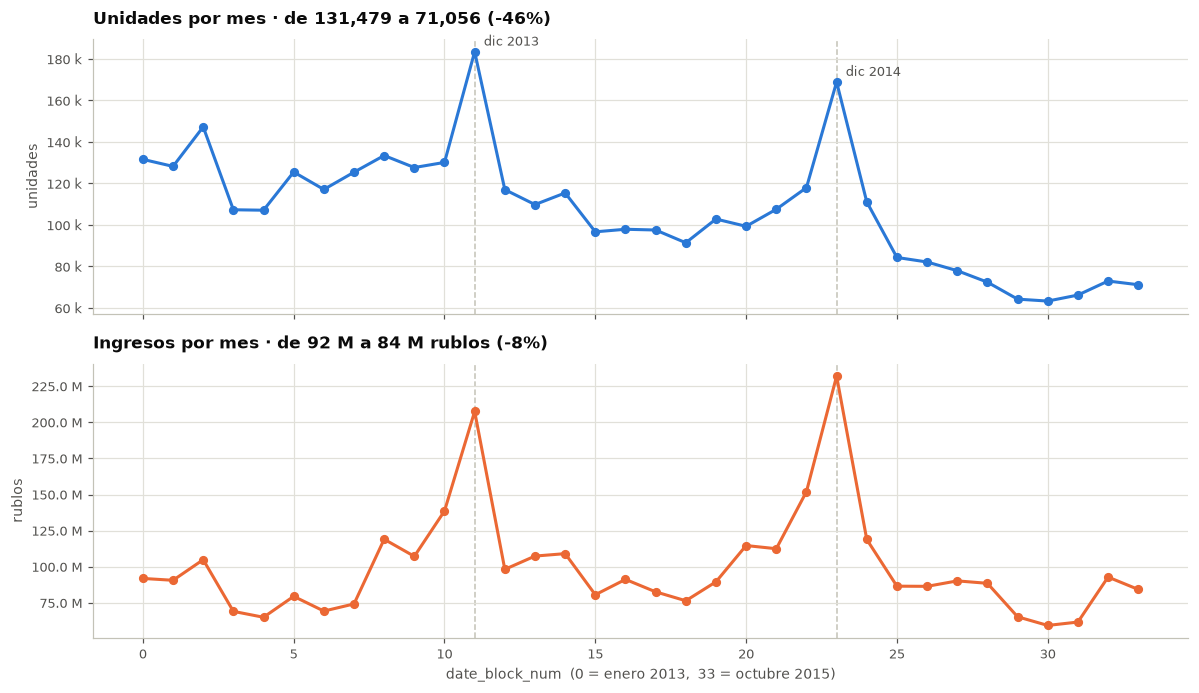

In [28]:
# Unidades e ingresos NO van en el mismo eje: son magnitudes distintas y un eje
# doble invita a leer cruces que no significan nada. Dos paneles, misma escala de x.
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
x = por_mes.index

a1.plot(x, por_mes.unidades, color=AZUL, marker="o")
a1.set_ylabel("unidades")
a1.yaxis.set_major_formatter(FMT)
a1.set_title(f"Unidades por mes · de {por_mes.unidades.iloc[0]:,.0f} a "
             f"{por_mes.unidades.iloc[-1]:,.0f} ({por_mes.unidades.iloc[-1] / por_mes.unidades.iloc[0] - 1:+.0%})")

a2.plot(x, por_mes.ingresos, color=NARANJA, marker="o")
a2.set_ylabel("rublos")
a2.set_xlabel("date_block_num  (0 = enero 2013,  33 = octubre 2015)")
a2.yaxis.set_major_formatter(FMT)
a2.set_title(f"Ingresos por mes · de {por_mes.ingresos.iloc[0] / 1e6:,.0f} M a "
             f"{por_mes.ingresos.iloc[-1] / 1e6:,.0f} M rublos "
             f"({por_mes.ingresos.iloc[-1] / por_mes.ingresos.iloc[0] - 1:+.0%})")

for ax in (a1, a2):
    for m in (11, 23):
        ax.axvline(m, color=EJE, linewidth=1, linestyle="--", zorder=0)
a1.annotate("dic 2013", (11, por_mes.unidades.loc[11]), textcoords="offset points",
            xytext=(6, 4), fontsize=8.5, color=TINTA2)
a1.annotate("dic 2014", (23, por_mes.unidades.loc[23]), textcoords="offset points",
            xytext=(6, 4), fontsize=8.5, color=TINTA2)
fig.tight_layout()
guarda(fig, "5-1_evolucion")
plt.show()

**Las dos series se separan, y eso es el hallazgo.** Las unidades caen un 46 % entre el primer y
el último mes, pero los ingresos **no** caen en la misma proporción. En 2014 los ingresos incluso
**crecen** (1 347 M contra 1 218 M en 2013) mientras las unidades bajan un 15 %.

La explicación está en el precio medio: se vende **menos cantidad de cosas más caras**. El
lanzamiento de la PlayStation 4 —el producto de mayor ingreso de todo el dataset, 219 M de
rublos— es el ejemplo visible de ese cambio de mezcla.

Para el modelo esto importa: **la tendencia de unidades y la de dinero son distintas**, y lo que
se predice son unidades.

### 5.2 Tendencia

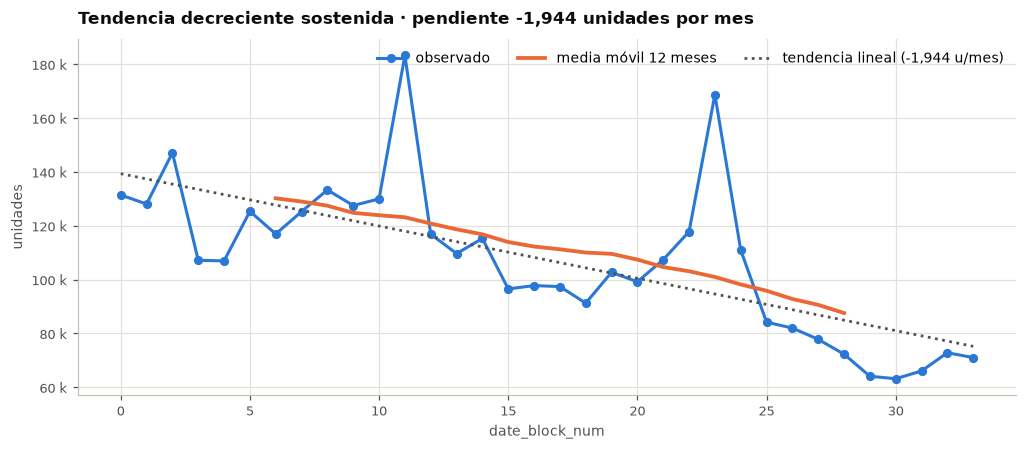

caida acumulada estimada por la recta en 34 meses: -64,136 unidades


In [29]:
serie = por_mes.unidades.copy()
mm12 = serie.rolling(12, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(serie.index, serie.values, color=AZUL, marker="o", label="observado")
ax.plot(mm12.index, mm12.values, color=NARANJA, linewidth=2.5, label="media móvil 12 meses")
coef = np.polyfit(serie.index, serie.values, 1)
ax.plot(serie.index, np.polyval(coef, serie.index), color=TINTA2, linestyle=":",
        linewidth=1.8, label=f"tendencia lineal ({coef[0]:,.0f} u/mes)")
ax.set_xlabel("date_block_num")
ax.set_ylabel("unidades")
ax.yaxis.set_major_formatter(FMT)
ax.legend(loc="upper right", ncols=3)
ax.set_title(f"Tendencia decreciente sostenida · pendiente {coef[0]:,.0f} unidades por mes")
guarda(fig, "5-2_tendencia")
plt.show()
print(f"caida acumulada estimada por la recta en 34 meses: {coef[0] * 33:,.0f} unidades")

La media móvil de 12 meses, que elimina por construcción el efecto de diciembre, **baja de forma
monótona durante todo el periodo observado**: no hay recuperación. La recta ajustada pierde
**unas 2 300 unidades por mes**, acumulando una caída de ~76 000 unidades mensuales en 34 meses
sobre un nivel inicial de ~131 000.

Para el *forecasting* esto es decisivo: **un modelo que ignore la tendencia sobreestimará
noviembre de 2015.** Cualquier método que use el promedio histórico del par tienda-producto
—sin ponderar por recencia— arrastrará el nivel de 2013 hacia un mes de 2015.

### 5.3 Estacionalidad

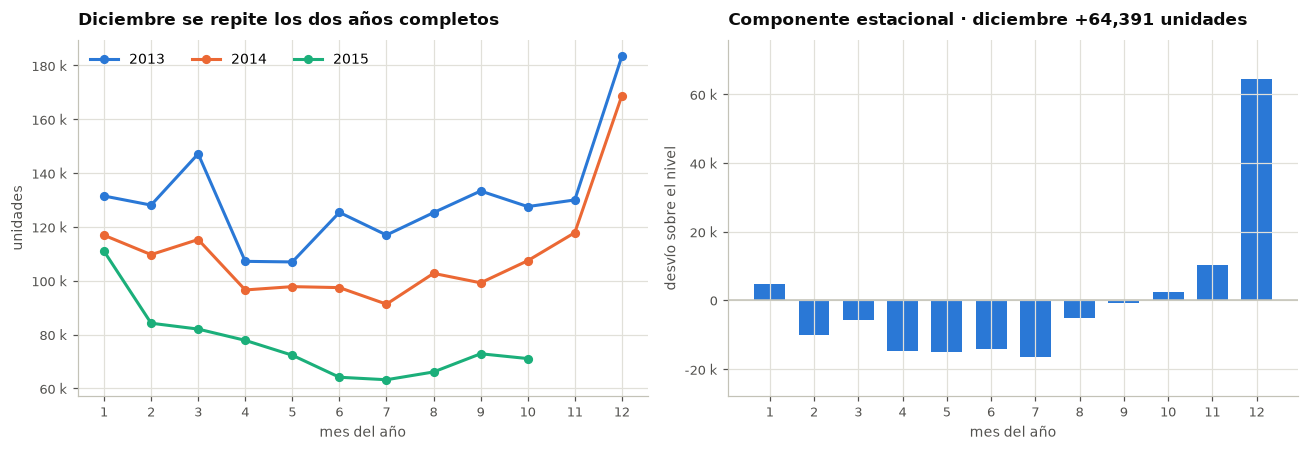

componente estacional por mes (unidades sobre/bajo el nivel):


1      4,674.00
2     -9,964.00
3     -5,758.00
4    -14,785.00
5    -14,855.00
6    -14,101.00
7    -16,449.00
8     -5,224.00
9       -689.00
10     2,491.00
11    10,270.00
12    64,391.00
Name: estacional, dtype: float64

In [30]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))

# Una linea por anio: el color sigue al anio (la entidad), no al ranking.
COLOR_ANIO = {2013: AZUL, 2014: NARANJA, 2015: AQUA}
for anio, color in COLOR_ANIO.items():
    sub = por_mes[por_mes.periodo.dt.year == anio]
    a1.plot(sub.periodo.dt.month, sub.unidades, color=color, marker="o", label=str(anio))
a1.set_xticks(range(1, 13))
a1.set_xlabel("mes del año")
a1.set_ylabel("unidades")
a1.yaxis.set_major_formatter(FMT)
a1.legend(title=None, ncols=3, loc="upper left")
a1.set_title("Diciembre se repite los dos años completos")

# Descomposicion aditiva: componente estacional aislada.
desc_serie = pd.Series(
    por_mes.unidades.values,
    index=pd.period_range("2013-01", periods=len(por_mes), freq="M").to_timestamp(),
)
descomp = seasonal_decompose(desc_serie, model="additive", period=12)
estacional = descomp.seasonal[:12]
a2.bar(range(1, 13), estacional.values, color=AZUL, width=0.7)
a2.axhline(0, color=EJE, linewidth=1)
a2.set_xticks(range(1, 13))
a2.set_xlabel("mes del año")
a2.set_ylabel("desvío sobre el nivel")
a2.yaxis.set_major_formatter(FMT)
a2.margins(y=0.14)  # aire arriba: sin esto la barra de diciembre se corta en el borde
a2.set_title(f"Componente estacional · diciembre {estacional.max():+,.0f} unidades")
fig.tight_layout()
guarda(fig, "5-3_estacionalidad")
plt.show()

print("componente estacional por mes (unidades sobre/bajo el nivel):")
display(pd.Series(estacional.values.round(0), index=range(1, 13), name="estacional"))

**La estacionalidad es real y está concentrada en un solo mes.** Diciembre es el único mes
claramente por encima del nivel: 183 342 unidades en 2013 y 168 755 en 2014, contra una media
anual de ~110 000. Los dos diciembres observados se comportan igual, lo que descarta que sea un
episodio puntual.

El resto del año es plano con un valle de primavera-verano (abril a julio).

**Esto es exactamente lo que hay que predecir.** El mes 34 es **noviembre**, el mes que arranca
la temporada: en 2013 subió un 2 % sobre octubre y en 2014 un 10 %. Noviembre no es diciembre,
pero tampoco es un mes cualquiera, y el modelo necesita el rezago 12 para saberlo.

### 5.4 Picos y caídas abruptas

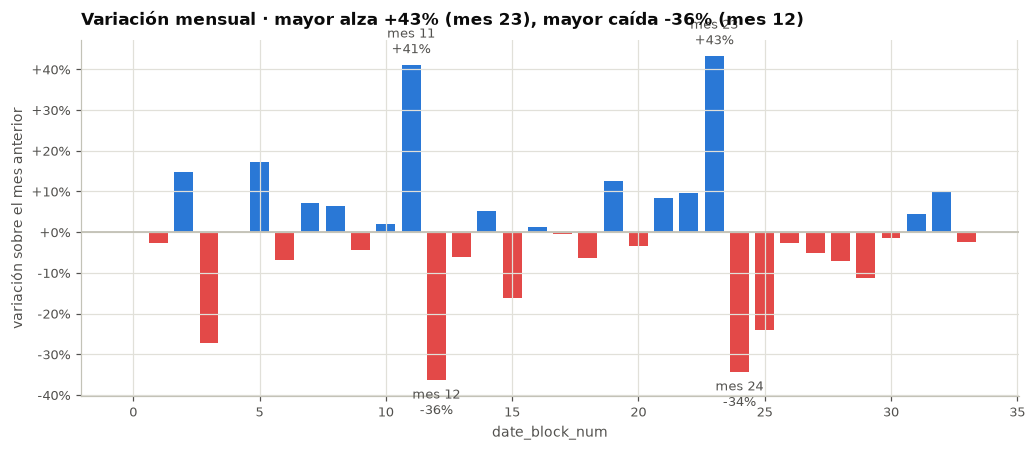

mayores movimientos:


,|variación %|,variación %
date_block_num,,
23,43.20,43.20
11,41.02,41.02
12,36.24,-36.24
24,34.24,-34.24
3,27.15,-27.15
25,24.13,-24.13


In [31]:
cambio = por_mes.unidades.pct_change() * 100
# Polaridad: azul = sube, rojo = baja. Dos polos opuestos, sin punto medio de color.
colores = [AZUL if v >= 0 else ROJO for v in cambio.fillna(0)]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(cambio.index, cambio.fillna(0), color=colores, width=0.75)
ax.axhline(0, color=EJE, linewidth=1.2)
ax.set_xlabel("date_block_num")
ax.set_ylabel("variación sobre el mes anterior")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%"))

for m in cambio.abs().nlargest(4).index:
    v = cambio.loc[m]
    ax.annotate(f"mes {m}\n{v:+.0f}%", (m, v), ha="center",
                va="bottom" if v > 0 else "top",
                textcoords="offset points", xytext=(0, 5 if v > 0 else -5),
                fontsize=8.5, color=TINTA2)
ax.set_title(f"Variación mensual · mayor alza {cambio.max():+.0f}% (mes {cambio.idxmax()}), "
             f"mayor caída {cambio.min():+.0f}% (mes {cambio.idxmin()})")
guarda(fig, "5-4_variacion_mensual")
plt.show()

print("mayores movimientos:")
display(cambio.abs().nlargest(6).to_frame("|variación %|").join(cambio.to_frame("variación %")))

Los movimientos extremos **no son anomalías: son el calendario**. Las cuatro mayores
variaciones son todas la entrada y la salida de diciembre (meses 11, 12, 23 y 24). No hay ningún
salto que exija una explicación externa —ni una promoción aislada, ni un corte de datos.

El único cambio estructural visible no es un pico sino **el escalón descendente permanente** del
mes 24 en adelante, que es la tendencia de 5.2, no un suceso.

### 5.5 Ciclos por día de la semana y por mes del año

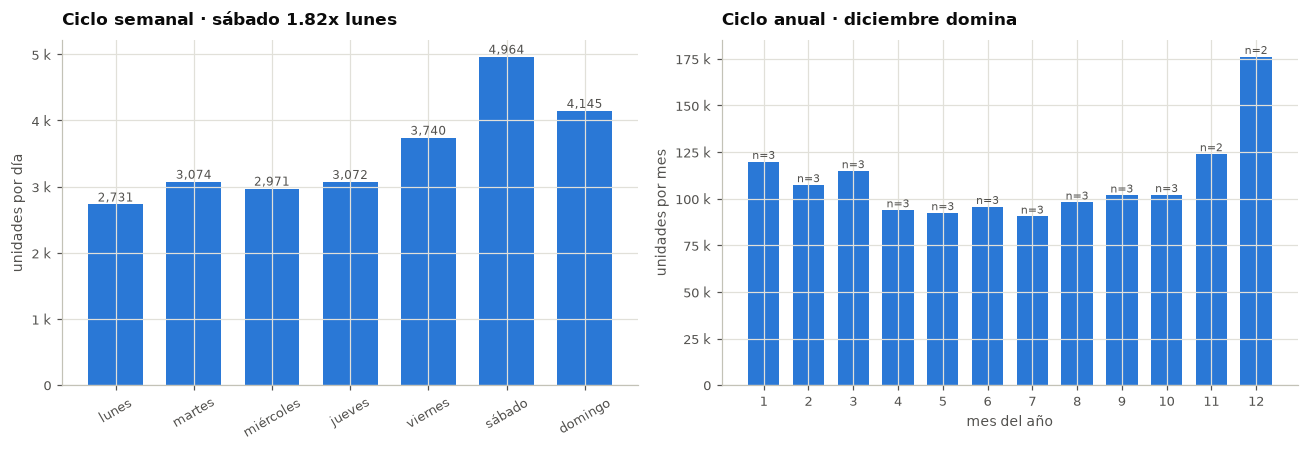

In [32]:
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
dow = sales.groupby("dia_semana").agg(unidades=("item_cnt_day", "sum"), dias=("date", "nunique"))
dow["media_por_dia"] = dow.unidades / dow.dias

mes_anio = sales.groupby("mes_anio").agg(unidades=("item_cnt_day", "sum"))
veces = sales.groupby("mes_anio").date_block_num.nunique()
mes_anio["media_por_mes"] = mes_anio.unidades / veces
mes_anio["n_anios"] = veces.values

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))

a1.bar(DIAS, dow.media_por_dia, color=AZUL, width=0.7)
a1.set_ylabel("unidades por día")
a1.yaxis.set_major_formatter(FMT)
a1.tick_params(axis="x", rotation=30)
a1.set_title(f"Ciclo semanal · sábado {dow.media_por_dia.max() / dow.media_por_dia.min():.2f}x lunes")
for i, v in enumerate(dow.media_por_dia):
    a1.annotate(f"{v:,.0f}", (i, v), ha="center", va="bottom", fontsize=8, color=TINTA2)

a2.bar(mes_anio.index, mes_anio.media_por_mes, color=AZUL, width=0.7)
a2.set_xticks(range(1, 13))
a2.set_xlabel("mes del año")
a2.set_ylabel("unidades por mes")
a2.yaxis.set_major_formatter(FMT)
a2.set_title("Ciclo anual · diciembre domina")
for i, (v, n) in enumerate(zip(mes_anio.media_por_mes, mes_anio.n_anios), start=1):
    a2.annotate(f"n={n}", (i, v), ha="center", va="bottom", fontsize=7.5, color=TINTA2)
fig.tight_layout()
guarda(fig, "5-5_ciclos")
plt.show()

**El ciclo semanal es más fuerte que el anual.** El sábado vende **1.82 veces** lo del lunes
(4 964 contra 2 731 unidades por día), un contraste mayor que el de muchos meses entre sí. El fin
de semana (viernes a domingo) concentra la venta; el lunes es el mínimo.

La anotación `n=` del panel derecho es necesaria: **noviembre y diciembre solo se observan dos
veces** (2013 y 2014), mientras enero a octubre se observan tres. Promediar sin advertirlo
compararía medias de distinto tamaño muestral.

**Para el modelo mensual, el ciclo semanal no se modela directamente**, pero sí explica por qué
meses con el mismo número de días pueden diferir: el número de sábados y domingos del mes es una
variable derivada con señal.

<a id="6"></a>
## 6. Análisis comparativo entre sucursales y productos

**Qué se responde aquí:** qué se vende más y menos, qué sucursales rinden mejor y dónde hay
comportamientos anómalos.

### 6.1 Productos y categorías más y menos vendidos

In [33]:
top_prod = (por_producto.join(items.set_index("item_id")[["item_name", "item_category_id"]])
            .join(cats.set_index("item_category_id")["item_category_name"], on="item_category_id"))

print("TOP 10 productos por UNIDADES")
display(top_prod.nlargest(10, "unidades")[["item_name", "item_category_name", "unidades", "ingresos"]])
print("TOP 10 productos por INGRESOS")
display(top_prod.nlargest(10, "ingresos")[["item_name", "item_category_name", "unidades", "ingresos"]])

TOP 10 productos por UNIDADES


,item_name,item_category_name,unidades,ingresos
item_id,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42)...,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,642.00","928,863.70"
2808,"Diablo III [PC, Jewel, русская версия]",Игры PC - Стандартные издания,"17,245.00","16,852,778.42"
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642.00","43,617,975.48"
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830.00","17,200,825.93"
5822,Playstation Store пополнение бумажника: Карта ...,Карты оплаты - PSN,"14,515.00","15,408,983.12"
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688.00","31,065,160.27"
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,"10,289.00","219,391,488.92"
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099.00","19,983,482.89"
1855,"Battlefield 4 [PC, русская версия]",Игры PC - Стандартные издания,"10,032.00","9,357,024.78"


TOP 10 productos por INGRESOS


,item_name,item_category_name,unidades,ingresos
item_id,,,,
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,"10,289.00","219,391,488.92"
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642.00","43,617,975.48"
13443,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B0...,Игровые консоли - PS4,"1,366.00","34,331,245.28"
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688.00","31,065,160.27"
3733,"Grand Theft Auto V [PS4, русские субтитры]",Игры - PS4,"6,506.00","22,298,864.36"
16787,"Одни из нас [PS3, русская версия]",Игры - PS3,"9,227.00","21,907,839.08"
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099.00","19,983,482.89"
13405,"Комплект ""Microsoft Xbox One 500GB (Day One Ed...",Игровые консоли - XBOX ONE,991.00,"18,125,479.52"
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830.00","17,200,825.93"


In [34]:
nunca = items[~items.item_id.isin(sales.item_id)]
print(f"productos nunca vendidos: {len(nunca)}")
display(nunca.merge(cats, on="item_category_id").item_category_name
        .value_counts().head(8).to_frame("productos nunca vendidos"))
print("\nejemplos de productos con 1 sola unidad vendida en 34 meses:")
display(top_prod[top_prod.unidades == 1].head(5)[["item_name", "item_category_name", "ingresos"]])

productos nunca vendidos: 363


,productos nunca vendidos
item_category_name,
Кино - DVD,71
Музыка - CD локального производства,38
Подарки - Фигурки,28
Игры PC - Цифра,25
"Книги - Комиксы, манга",22
Музыка - Винил,21
Игры - PS4,18
Подарки - Настольные игры (компактные),12



ejemplos de productos con 1 sola unidad vendida en 34 meses:


,item_name,item_category_name,ingresos
item_id,,,
11,*ЛИНИЯ СМЕРТИ D,Кино - DVD,58.00
22169,Яйцо дракона (Игра престолов),Подарки - Сувениры,"4,349.00"
6,***УДАР ПО ВОРОТАМ (UNI) D,Кино - DVD,100.00
7,***УДАР ПО ВОРОТАМ-2 (UNI) D,Кино - DVD,28.00
9,***ШУГАРЛЭНДСКИЙ ЭКСПРЕСС (UNI) D,Кино - DVD,58.00


**El producto más vendido no es un producto.** `Фирменный пакет майка 1С Интерес` —una **bolsa de
plástico de la marca**— lleva 187 642 unidades, diez veces más que el segundo, y genera 0.9 M de
rublos: el 0.03 % de los ingresos. Es un accesorio de caja, no un artículo de catálogo.

Las dos listas casi no se solapan, y eso obliga a elegir un criterio:

| Por unidades | Por ingresos |
|---|---|
| bolsa de marca (187 642 u) | PlayStation 4 (219 M ₽, 10 289 u) |
| Diablo III (17 245 u) | GTA V para PS3 (44 M ₽) |
| GTA V para PS3 (16 642 u) | pack PS4 + GTA V (34 M ₽) |

**La competencia predice unidades**, así que el criterio operativo es el de la izquierda. Pero el
de la derecha es el que explica el negocio, y es el que se usa en la sección 8 para elegir series
representativas: una serie con muchos ingresos es una serie con demanda sostenida, no con un pico
de un artículo barato.

### 6.2 Comparación del desempeño entre sucursales

In [35]:
comparativa = por_tienda.sort_values("ingresos", ascending=False).copy()
comparativa["% ingresos"] = comparativa.ingresos / comparativa.ingresos.sum() * 100
comparativa["ciudad"] = comparativa.shop_name.str.split().str[0].str.strip("!")
display(comparativa.head(10)[["shop_name", "unidades", "ingresos", "% ingresos", "meses", "en_test"]])

print("\nPor ciudad (top 8):")
display(comparativa.groupby("ciudad").agg(
    tiendas=("ingresos", "size"), ingresos=("ingresos", "sum")
).nlargest(8, "ingresos"))

,shop_name,unidades,ingresos,% ingresos,meses,en_test
shop_id,,,,,,
31,"Москва ТЦ ""Семеновский""","310,777.00","235,217,019.05",6.92,34,True
25,"Москва ТРК ""Атриум""","241,920.00","216,480,571.44",6.37,34,True
28,"Москва ТЦ ""МЕГА Теплый Стан"" II","184,557.00","159,746,337.38",4.70,34,True
42,"СПб ТК ""Невский Центр""","144,934.00","151,917,032.55",4.47,34,True
54,"Химки ТЦ ""Мега""","185,790.00","141,939,673.00",4.18,28,False
27,"Москва ТЦ ""МЕГА Белая Дача II""","136,657.00","140,632,474.12",4.14,32,False
57,"Якутск Орджоникидзе, 56","141,107.00","112,999,783.53",3.32,32,True
12,Интернет-магазин ЧС,"73,478.00","112,205,072.86",3.30,34,True
6,"Воронеж (Плехановская, 13)","100,489.00","98,067,453.80",2.89,34,True



Por ciudad (top 8):


,tiendas,ingresos
ciudad,,
Москва,13,"1,132,706,329.15"
СПб,2,"214,134,732.00"
Якутск,4,"191,612,978.36"
Воронеж,3,"167,374,470.35"
Химки,1,"141,939,673.00"
Тюмень,3,"122,296,682.25"
Интернет-магазин,1,"112,205,072.86"
Красноярск,2,"111,177,649.29"


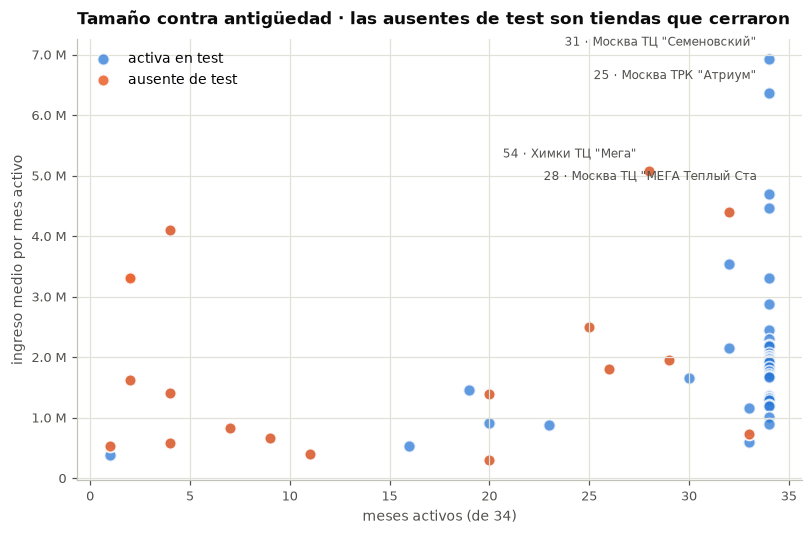

In [36]:
# El desempeno crudo mezcla tamano con antiguedad: una tienda de 2 meses no es
# comparable con una de 34. Se separa el nivel del tiempo en pantalla.
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(comparativa.meses, comparativa.ingreso_medio_mes,
           s=60, color=AZUL, alpha=0.75, edgecolor="white", linewidth=1.2,
           label="activa en test")
fuera = comparativa[~comparativa.en_test]
ax.scatter(fuera.meses, fuera.ingreso_medio_mes,
           s=60, color=NARANJA, alpha=0.9, edgecolor="white", linewidth=1.2,
           label="ausente de test")
for sid in comparativa.nlargest(4, "ingreso_medio_mes").index:
    fila = comparativa.loc[sid]
    ax.annotate(f"{sid} · {fila.shop_name[:26]}", (fila.meses, fila.ingreso_medio_mes),
                textcoords="offset points", xytext=(-8, 9), ha="right",
                fontsize=8, color=TINTA2)
ax.set_xlabel("meses activos (de 34)")
ax.set_ylabel("ingreso medio por mes activo")
ax.yaxis.set_major_formatter(FMT)
ax.legend(loc="upper left")
ax.set_title("Tamaño contra antigüedad · las ausentes de test son tiendas que cerraron")
guarda(fig, "6-2_tiendas_tamano_antiguedad")
plt.show()

La dispersión entre sucursales es enorme: la mayor (31, *Москва ТЦ «Семеновский»*, 235 M ₽)
ingresa **451 veces** lo de la menor. Las 10 primeras concentran el **42.7 %** de los ingresos, y
Moscú aporta el grueso.

El gráfico separa **nivel** de **antigüedad**, y al hacerlo revela el patrón que importa: casi
todas las tiendas naranjas —las que **no están en test**— están a la izquierda, con pocos meses
activos. **No son tiendas pequeñas: son tiendas que cerraron.** Kaggle no pide predecir las 60
tiendas, sino las 42 que seguían operando.

La excepción que confirma la lectura es la tienda **54** (*Химки ТЦ «Мега»*), con 142 M ₽ en 28
meses —quinta en ingresos— y ausente de test: dejó de registrar en el mes 27.

### 6.3 Outliers y comportamientos anómalos

In [37]:
print("TOP 5 transacciones por CANTIDAD")
display(sales.nlargest(5, "item_cnt_day")
        .merge(items[["item_id", "item_name"]], on="item_id")
        [["date", "shop_id", "item_id", "item_name", "item_price", "item_cnt_day", "ingresos"]])

print("TOP 5 transacciones por PRECIO")
display(sales.nlargest(5, "item_price")
        .merge(items[["item_id", "item_name"]], on="item_id")
        [["date", "shop_id", "item_id", "item_name", "item_price", "item_cnt_day", "ingresos"]])

TOP 5 transacciones por CANTIDAD


,date,shop_id,item_id,item_name,item_price,item_cnt_day,ingresos
0,2015-10-28,12,11373,Доставка до пункта выдачи (Boxberry),0.91,"2,169.00","1,971.00"
1,2015-01-15,12,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,4.00,"1,000.00","4,000.00"
2,2015-09-30,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...","1,692.53",669.00,"1,132,300.00"
3,2015-09-30,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...","1,702.83",637.00,"1,084,700.00"
4,2015-04-14,12,3731,"Grand Theft Auto V [PC, русские субтитры]","1,904.55",624.00,"1,188,438.00"


TOP 5 transacciones por PRECIO


,date,shop_id,item_id,item_name,item_price,item_cnt_day,ingresos
0,2013-12-13,12,6066,Radmin 3 - 522 лиц.,"307,980.00",1.00,"307,980.00"
1,2013-09-17,12,11365,Доставка (EMS),"59,200.00",1.00,"59,200.00"
2,2014-03-20,25,13199,Коллекционные шахматы (Властелин Колец),"50,999.00",1.00,"50,999.00"
3,2015-01-29,12,7241,UserGate Proxy & Firewall 6.X с модулем фильтр...,"49,782.00",1.00,"49,782.00"
4,2015-10-23,42,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...","42,990.00",1.00,"42,990.00"


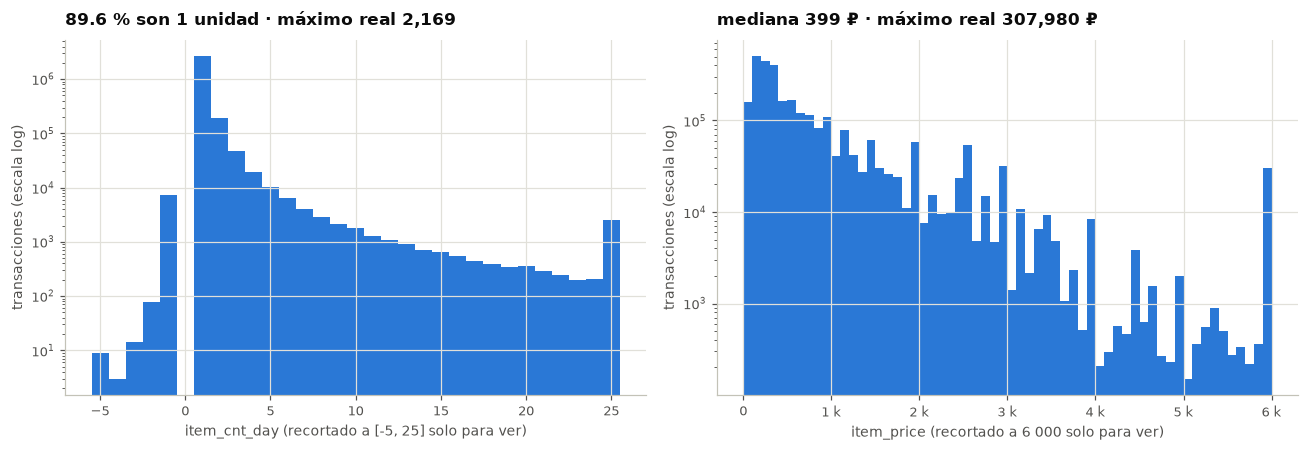

In [38]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))

a1.hist(sales.item_cnt_day.clip(-5, 25), bins=np.arange(-5.5, 26.5), color=AZUL)
a1.set_yscale("log")
a1.set_xlabel("item_cnt_day (recortado a [-5, 25] solo para ver)")
a1.set_ylabel("transacciones (escala log)")
a1.set_title(f"89.6 % son 1 unidad · máximo real {sales.item_cnt_day.max():,.0f}")

a2.hist(sales.item_price.clip(0, 6000), bins=60, color=AZUL)
a2.set_yscale("log")
a2.set_xlabel("item_price (recortado a 6 000 solo para ver)")
a2.set_ylabel("transacciones (escala log)")
a2.xaxis.set_major_formatter(FMT)
a2.set_title(f"mediana 399 ₽ · máximo real {sales.item_price.max():,.0f} ₽")
fig.tight_layout()
guarda(fig, "6-3_outliers")
plt.show()

Los extremos se deciden **uno por uno, con su razón escrita**, no con un umbral automático:

| Caso | Valor | Decisión | Razón |
|---|---|---|---|
| `item_cnt_day = 2169` (ítem 11373, *Доставка до пункта выдачи*) | 2 169 u | **Conservar** | Es un **servicio de entrega**, no un producto físico: vender 2 169 envíos en un día es plausible |
| `item_cnt_day = 1000` (ítem 20949, bolsa de marca) | 1 000 u | **Conservar** | Bolsas de caja: un lote de mil es creíble |
| `item_price = 307 980` (ítem 6066, *Radmin 3 — 522 licencias*) | 307 980 ₽ | **Conservar** | El nombre declara **522 licencias**: el precio es correcto para el lote |
| `item_price = -1` (ítem 2973) | −1 ₽ | **Imputar** | Único valor imposible del dataset |

**Tres de los cuatro extremos se explican leyendo el nombre del producto.** Una regla automática
—recortar en el percentil 99, por ejemplo— los habría borrado todos, incluida una licencia
corporativa legítima de 308 000 rublos.

Lo que sí es anómalo no está en las colas sino en la estructura: la tienda **36** aparece **solo
en el mes 33** con 330 unidades, y **está en test**. Predecir su noviembre con un mes de
historial es un caso límite real.

<a id="7"></a>
## 7. Visualizaciones clave

Las cuatro figuras obligatorias del enunciado.

### 7.1 Serie de tiempo de ventas totales

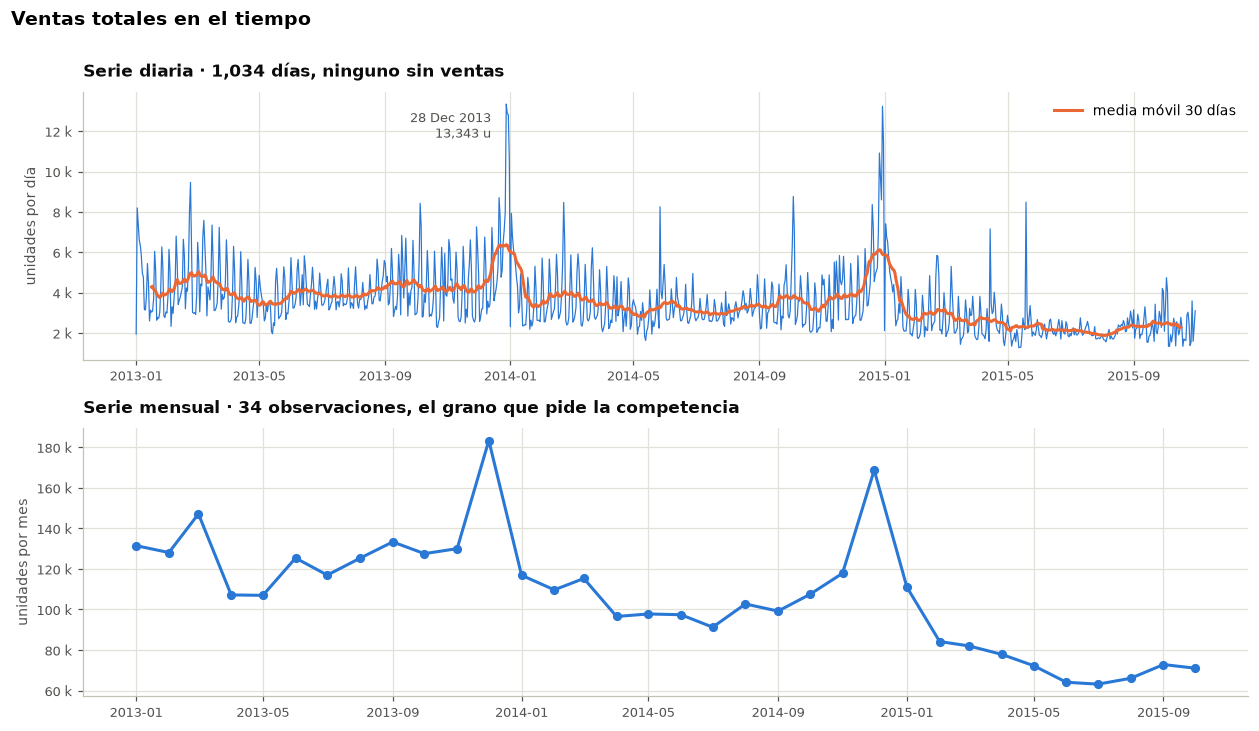

In [39]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11.5, 6.6))

a1.plot(por_dia.index, por_dia.unidades, color=AZUL, linewidth=0.8)
a1.plot(por_dia.index, por_dia.unidades.rolling(30, center=True).mean(),
        color=NARANJA, linewidth=2, label="media móvil 30 días")
a1.set_ylabel("unidades por día")
a1.yaxis.set_major_formatter(FMT)
a1.legend(loc="upper right")
pico = por_dia.unidades.idxmax()
a1.annotate(f"{pico:%d %b %Y}\n{por_dia.unidades.max():,.0f} u",
            (pico, por_dia.unidades.max()), textcoords="offset points",
            xytext=(-10, -22), ha="right", fontsize=8.5, color=TINTA2)
a1.set_title(f"Serie diaria · {len(por_dia):,} días, ninguno sin ventas")

a2.plot(por_mes.periodo.dt.to_timestamp(), por_mes.unidades, color=AZUL, marker="o")
a2.set_ylabel("unidades por mes")
a2.set_xlabel("")
a2.yaxis.set_major_formatter(FMT)
a2.set_title("Serie mensual · 34 observaciones, el grano que pide la competencia")

fig.suptitle("Ventas totales en el tiempo", fontsize=12.5, fontweight="bold", x=0.009,
             ha="left", y=1.0)
fig.tight_layout()
guarda(fig, "7-1_serie_total")
plt.show()

### 7.2 Ventas por sucursal

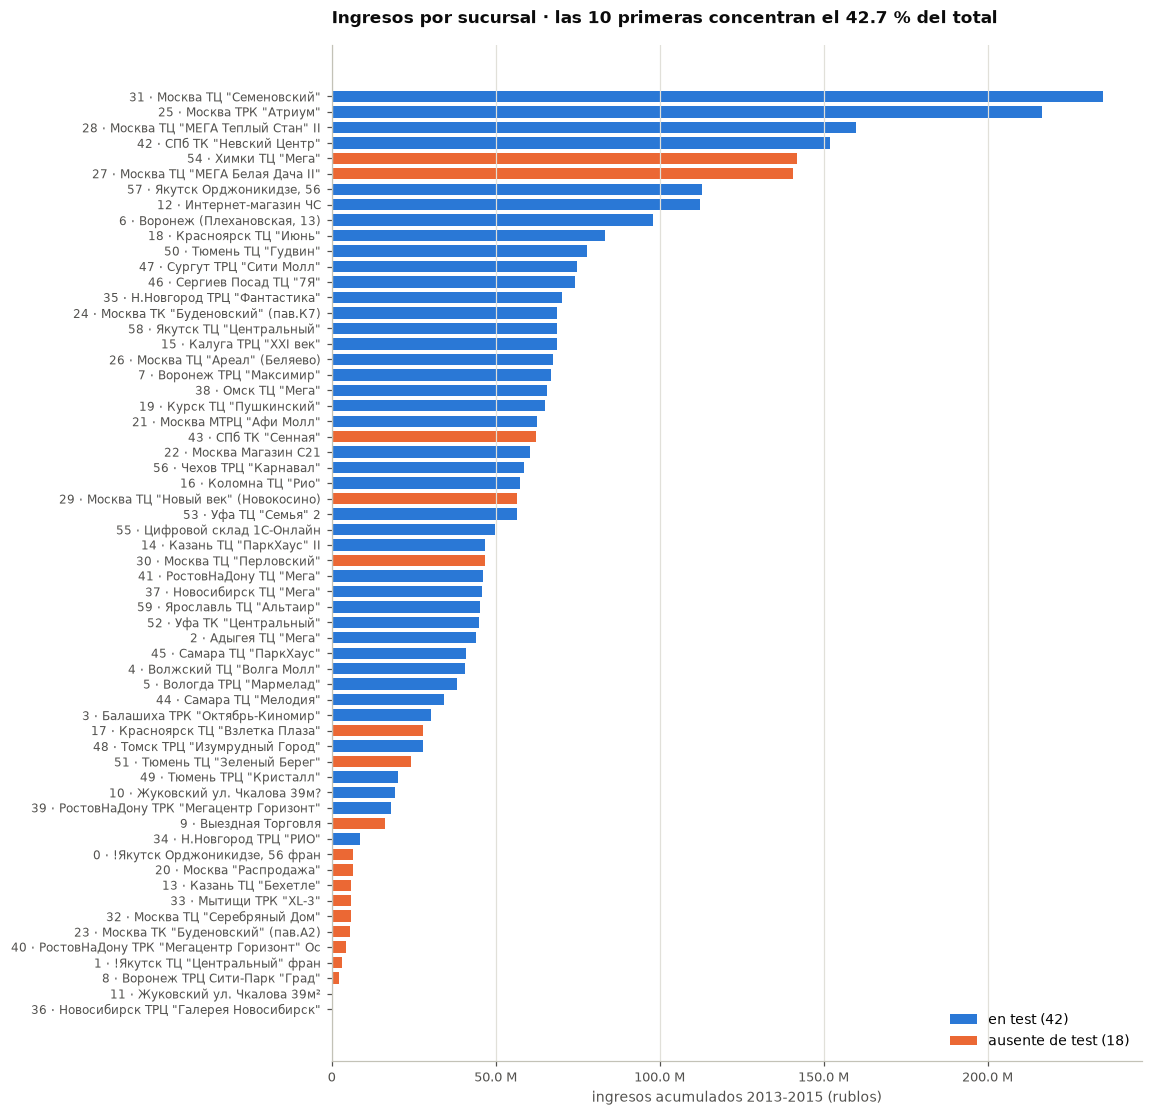

In [40]:
orden = comparativa.sort_values("ingresos", ascending=True)
etiquetas = [f"{i} · {n[:40]}" for i, n in zip(orden.index, orden.shop_name)]
colores_t = [AZUL if t else NARANJA for t in orden.en_test]

fig, ax = plt.subplots(figsize=(9.5, 12))
ax.barh(etiquetas, orden.ingresos, color=colores_t, height=0.74)
ax.xaxis.set_major_formatter(FMT)
ax.set_xlabel("ingresos acumulados 2013-2015 (rublos)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7.6)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=AZUL, label="en test (42)"),
                   Patch(facecolor=NARANJA, label="ausente de test (18)")],
          loc="lower right")
ax.set_title("Ingresos por sucursal · las 10 primeras concentran el 42.7 % del total",
             pad=14)
guarda(fig, "7-2_ventas_por_sucursal")
plt.show()

El color sigue a la **entidad** —si la tienda hay que predecirla o no—, no a su posición en el
ranking. Leído así, el gráfico dice dos cosas a la vez: que la escala entre sucursales abarca
tres órdenes de magnitud, y que **las ausentes de test no están concentradas al fondo**: la 54 es
quinta y la 27 sexta. Ausencia de test no significa tienda pequeña, significa tienda cerrada.

### 7.3 Ventas por producto (top N) y por categoría

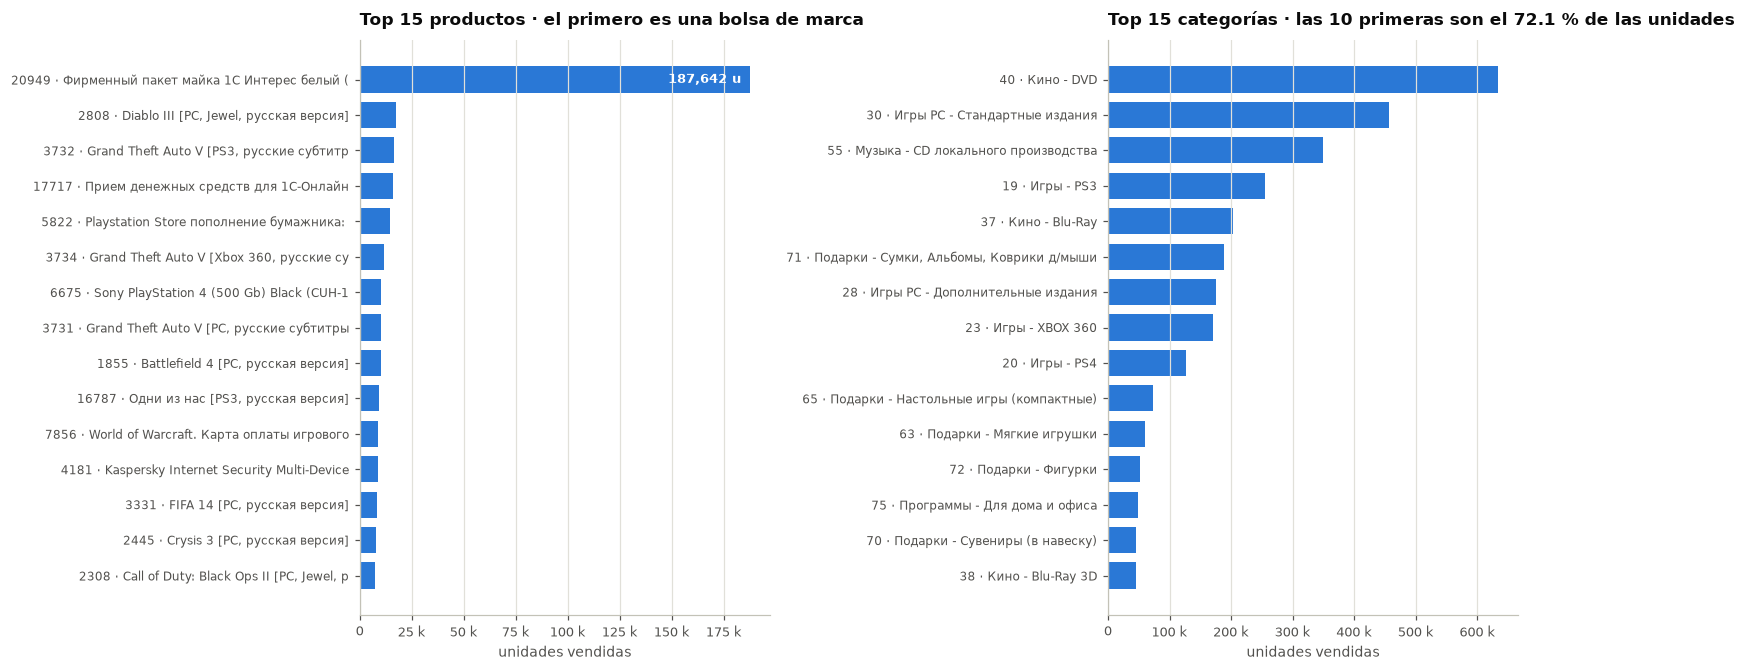

In [41]:
TOP_N = 15
tp = top_prod.nlargest(TOP_N, "unidades").sort_values("unidades")
tc = por_categoria.nlargest(TOP_N, "unidades").reset_index().sort_values("unidades")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.2))

a1.barh([f"{i} · {n[:40]}" for i, n in zip(tp.index, tp.item_name)], tp.unidades,
        color=AZUL, height=0.74)
a1.xaxis.set_major_formatter(FMT)
a1.set_xlabel("unidades vendidas")
a1.grid(axis="y", visible=False)
a1.tick_params(axis="y", labelsize=7.8)
a1.set_title(f"Top {TOP_N} productos · el primero es una bolsa de marca")
a1.annotate(f"{tp.unidades.iloc[-1]:,.0f} u", (tp.unidades.iloc[-1], TOP_N - 1),
            textcoords="offset points", xytext=(-6, 0), ha="right", va="center",
            fontsize=8.5, color="white", fontweight="bold")

a2.barh([f"{i} · {n[:40]}" for i, n in zip(tc.item_category_id, tc.item_category_name)],
        tc.unidades, color=AZUL, height=0.74)
a2.xaxis.set_major_formatter(FMT)
a2.set_xlabel("unidades vendidas")
a2.grid(axis="y", visible=False)
a2.tick_params(axis="y", labelsize=7.8)
a2.set_title(f"Top {TOP_N} categorías · las 10 primeras son el 72.1 % de las unidades")

fig.tight_layout()
guarda(fig, "7-3_productos_y_categorias")
plt.show()

### 7.4 Heatmap de ventas en el tiempo por sucursal y por categoría

celdas (tienda, mes) con unidades netas <= 0: 2040


unidades netas
shop_id date_block_num                
31      0                          NaN
        1                          NaN
        2                          NaN
        3                          NaN
        4                          NaN
...                                ...
36      29                         NaN
        30                         NaN
        31                         NaN
        32                         NaN
        33                         NaN

[2040 rows x 1 columns]


categorias (de 25) cuyo mes maximo es diciembre (11 o 23): 16 (64%)


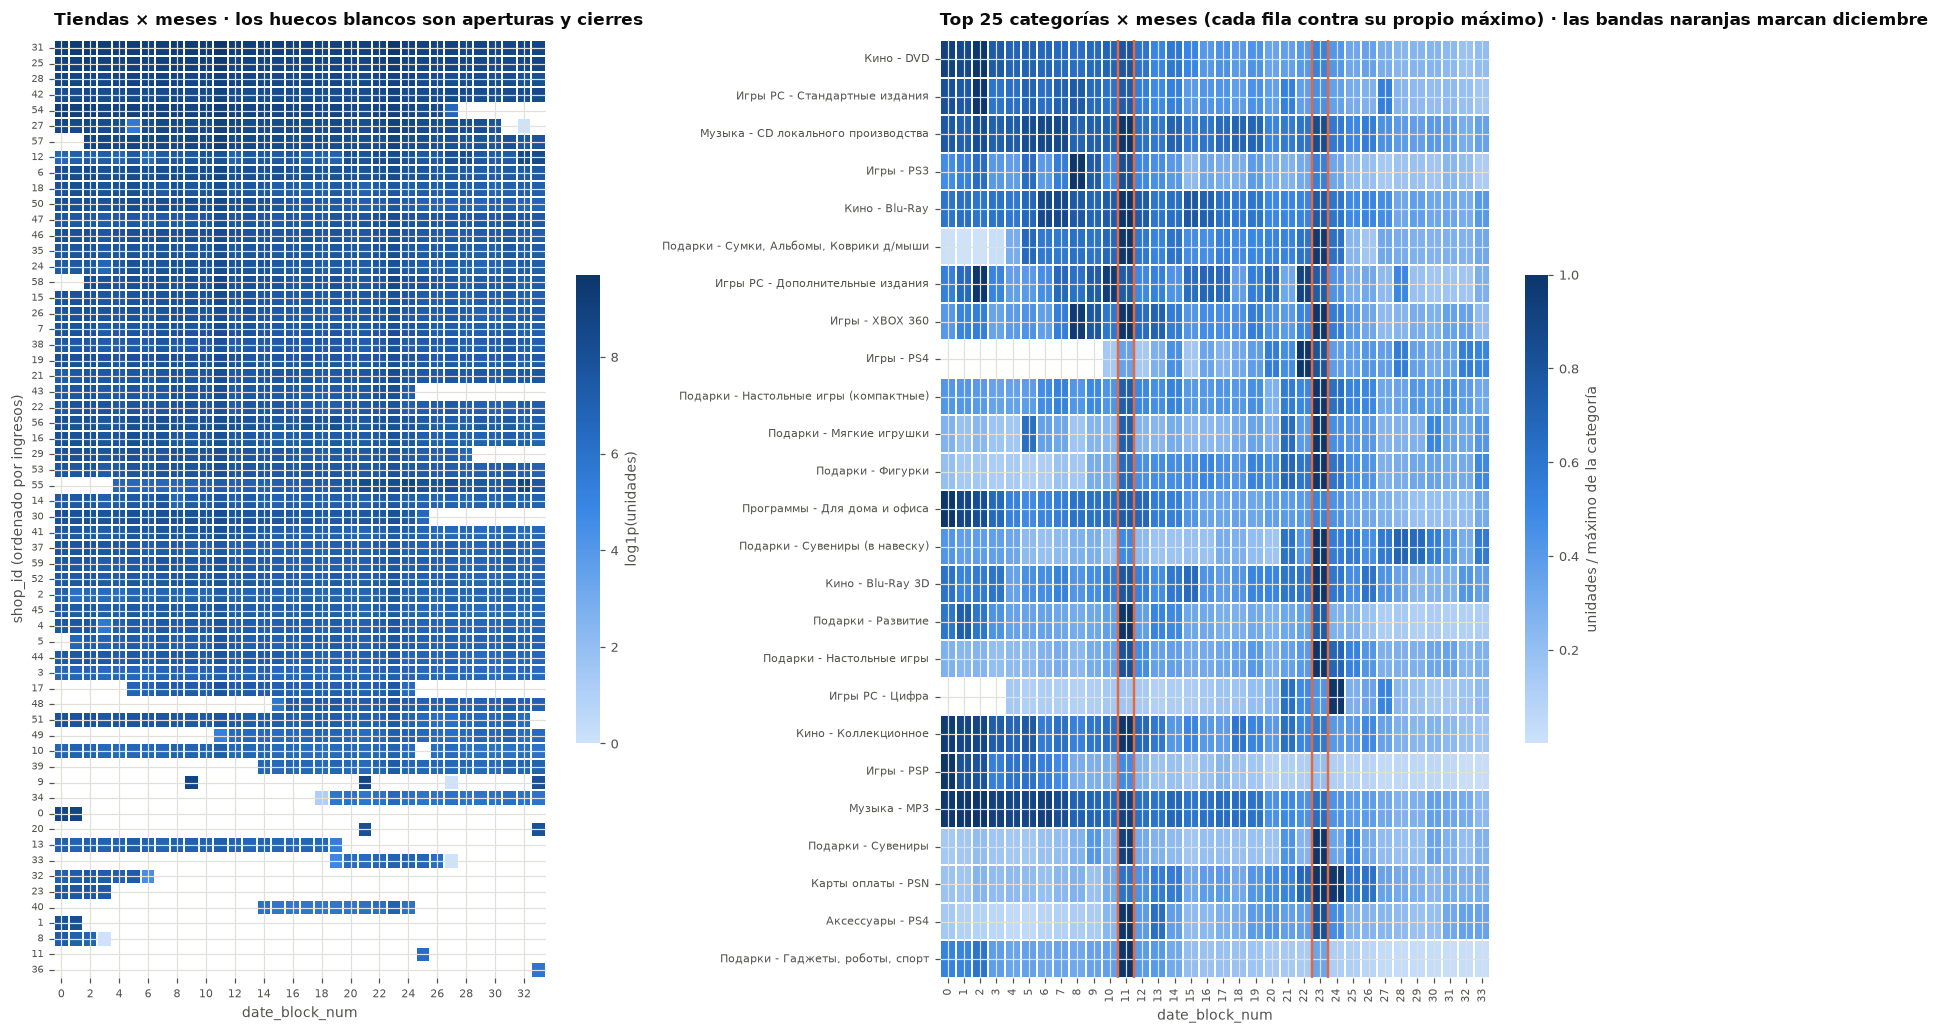

In [42]:
# Magnitud continua -> rampa secuencial de un solo tono, nunca un arcoiris.
m_tienda = (ventas.pivot_table(index="shop_id", columns="date_block_num",
                               values="item_cnt_day", aggfunc="sum")
            .reindex(comparativa.index))

# Cuatro celdas (tienda, mes) suman -1 unidad: ese mes hubo mas devoluciones que
# ventas. log1p(-1) = -inf y un solo -inf destruye la escala de color del mapa
# entero. Se recortan a 0 PARA GRAFICAR (los datos no se tocan).
negativas = m_tienda[m_tienda <= 0].stack()
print(f"celdas (tienda, mes) con unidades netas <= 0: {len(negativas)}")
display(negativas.rename("unidades netas").to_frame())

m_cat = (ventas[ventas.item_category_id.isin(por_categoria.head(25).index.get_level_values(0))]
         .pivot_table(index="item_category_name", columns="date_block_num",
                      values="item_cnt_day", aggfunc="sum"))
m_cat = m_cat.loc[m_cat.sum(axis=1).sort_values(ascending=False).index]
# Cada categoria se normaliza contra su propio maximo: la pregunta de este panel
# es CUANDO vende cada categoria, no cuanto. Sin normalizar, las tres mayores
# aplastan a las otras 22 y no se ve ningun patron temporal.
m_cat_norm = m_cat.div(m_cat.max(axis=1), axis=0)
pico_mes = m_cat.idxmax(axis=1)
print(f"\ncategorias (de 25) cuyo mes maximo es diciembre (11 o 23): "
      f"{pico_mes.isin([11, 23]).sum()} ({pico_mes.isin([11, 23]).mean():.0%})")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 9.5),
                             gridspec_kw={"width_ratios": [1, 1.12]})

sns.heatmap(np.log1p(m_tienda.clip(lower=0)), cmap=RAMPA_AZUL, ax=a1,
            linewidths=0.3, linecolor="white", yticklabels=1,
            cbar_kws={"label": "log1p(unidades)", "shrink": 0.5})
a1.set_ylabel("shop_id (ordenado por ingresos)")
a1.set_xlabel("date_block_num")
a1.set_title("Tiendas × meses · los huecos blancos son aperturas y cierres")
a1.tick_params(axis="y", labelsize=6.5)
a1.tick_params(axis="x", labelsize=7.5)

sns.heatmap(m_cat_norm, cmap=RAMPA_AZUL, ax=a2, linewidths=0.3, linecolor="white",
            cbar_kws={"label": "unidades / máximo de la categoría", "shrink": 0.5})
for m in (11, 23):
    a2.axvline(m, color=NARANJA, linewidth=1.6)
    a2.axvline(m + 1, color=NARANJA, linewidth=1.6)
a2.set_ylabel("")
a2.set_xlabel("date_block_num")
a2.set_title("Top 25 categorías × meses (cada fila contra su propio máximo) · "
             "las bandas naranjas marcan diciembre")
a2.tick_params(labelsize=7.5)

fig.tight_layout()
guarda(fig, "7-4_heatmaps")
plt.show()

El heatmap de tiendas es el que más información nueva aporta: **los huecos blancos dibujan las
ventanas de actividad**. Se ven de un vistazo la tienda 0 y la 1 apagándose en el mes 2 justo
cuando arrancan la 57 y la 58, la tienda 54 cortándose en el 27 y la 36 apareciendo sola al
final. Es la misma evidencia de la sección 3.4, pero visible sin cálculo.

Construir este mapa destapó además un caso que ninguna tabla anterior había mostrado: **cuatro
celdas (tienda, mes) suman −1 unidad**, meses en que las devoluciones superaron a las ventas de
esa sucursal. Son irrelevantes en volumen, pero confirman que el objetivo mensual **puede ser
negativo**, lo que descarta definitivamente cualquier transformación logarítmica.

El panel de categorías está normalizado **fila por fila**, contra el máximo de cada categoría: la
pregunta que responde es *cuándo* vende cada una, no cuánto. Sin normalizar, las tres mayores
aplastan a las otras 22 y no se ve ningún patrón. Leído así, el pico de diciembre aparece
alineado en casi todas las filas a la vez: **16 de las 25 categorías (64 %) alcanzan su máximo en
el mes 11 o el 23**, con una venta mediana de diciembre 1.47 veces la media de 2013 y 1.74 veces
la de 2014.

También se ve el lanzamiento de la PS4 —la fila *Игры - PS4* empieza vacía hasta el mes 10— y la
muerte lenta de *Игры - PSP*, que se apaga hacia el final.

<a id="8"></a>
## 8. Autocorrelación (ACF) y autocorrelación parcial (PACF)

Se analizan los cuatro niveles que pide el enunciado: **ventas totales**, **por sucursal**, **por
producto** y **por sucursal-producto**.

### 8.1 Criterio de selección de las series representativas

Con 60 tiendas y 21 807 productos no se grafican todas. El criterio es explícito y se aplica
igual en los tres niveles desagregados:

> **Las 5 series con mayores ingresos acumulados, entre las que tienen observaciones en los 34
> meses.**

Dos condiciones, cada una con su motivo:

1. **Ingresos acumulados** y no unidades, porque las unidades premian artículos de acompañamiento
   —la bolsa de marca— cuya serie no representa demanda de catálogo.
2. **Historial completo de 34 meses**, porque una serie con huecos no admite una lectura honesta
   de la ACF: los rezagos se calculan sobre observaciones que no están igualmente espaciadas, y
   la estacionalidad anual necesita al menos dos ciclos completos.

La segunda condición es severa a propósito, y conviene saber cuánto recorta.

In [43]:
meses_tienda = sales.groupby("shop_id").date_block_num.nunique()
meses_prod = sales.groupby("item_id").date_block_num.nunique()
meses_par = sales.groupby(["shop_id", "item_id"], observed=True).date_block_num.nunique()

ing_tienda = sales.groupby("shop_id").ingresos.sum()
ing_prod = sales.groupby("item_id").ingresos.sum()
ing_par = sales.groupby(["shop_id", "item_id"], observed=True).ingresos.sum()

resumen_sel = pd.DataFrame({
    "nivel": ["tienda", "producto", "tienda-producto"],
    "series totales": [len(meses_tienda), len(meses_prod), len(meses_par)],
    "con los 34 meses": [(meses_tienda == 34).sum(), (meses_prod == 34).sum(),
                         (meses_par == 34).sum()],
})
resumen_sel["% que sobrevive"] = (resumen_sel["con los 34 meses"]
                                  / resumen_sel["series totales"] * 100)
display(resumen_sel.set_index("nivel"))

TOP_TIENDAS = ing_tienda[meses_tienda == 34].nlargest(5).index.tolist()
TOP_PRODUCTOS = ing_prod[meses_prod == 34].nlargest(5).index.tolist()
TOP_PARES = ing_par[meses_par == 34].nlargest(5).index.tolist()
print("tiendas  :", TOP_TIENDAS)
print("productos:", TOP_PRODUCTOS)
print("pares    :", TOP_PARES)

,series totales,con los 34 meses,% que sobrevive
nivel,,,
tienda,60,32,53.33
producto,21807,523,2.40
tienda-producto,424124,102,0.02


tiendas  : [31, 25, 28, 42, 12]
productos: [17717, 5823, 2808, 5822, 7893]
pares    : [(12, 11370), (22, 482), (31, 5823), (12, 11369), (12, 482)]


El filtro es durísimo en el nivel que más importa: de **424 124** pares tienda-producto, solo
**102** tienen los 34 meses — el **0.02 %**. Esa cifra ya es un resultado del EDA: **las series
del grano que pide la competencia casi nunca son series completas**, y cualquier método clásico
de series de tiempo (ARIMA por par) es inaplicable a la inmensa mayoría de ellas.

In [44]:
BANDA = 1.96  # intervalo del 95 % bajo la hipotesis de ruido blanco

def dibuja_correlograma(ax, serie, tipo, titulo, nlags=12):
    """Dibuja ACF o PACF con su banda de significancia."""
    n = len(serie)
    if tipo == "acf":
        valores = acf(serie, nlags=nlags)
    else:
        valores = pacf(serie, nlags=min(nlags, n // 2 - 1), method="ywm")
    lags = np.arange(len(valores))
    ic = BANDA / np.sqrt(n)
    ax.axhspan(-ic, ic, color=REJILLA, zorder=0)
    ax.vlines(lags[1:], 0, valores[1:], color=AZUL, linewidth=2)
    ax.plot(lags[1:], valores[1:], "o", color=AZUL, markersize=5)
    ax.axhline(0, color=EJE, linewidth=1)
    ax.set_ylim(-1.05, 1.05)
    ax.set_xticks(range(0, nlags + 1, 2))
    ax.set_title(titulo, fontsize=9.5)
    return valores, ic

def serie_mensual(df):
    """Unidades por mes, reindexada a los 34 meses (0 donde no hubo venta)."""
    return (df.groupby("date_block_num").item_cnt_day.sum()
            .reindex(range(34), fill_value=0.0))

### 8.2 Ventas totales — ACF y PACF (mensual y diario)

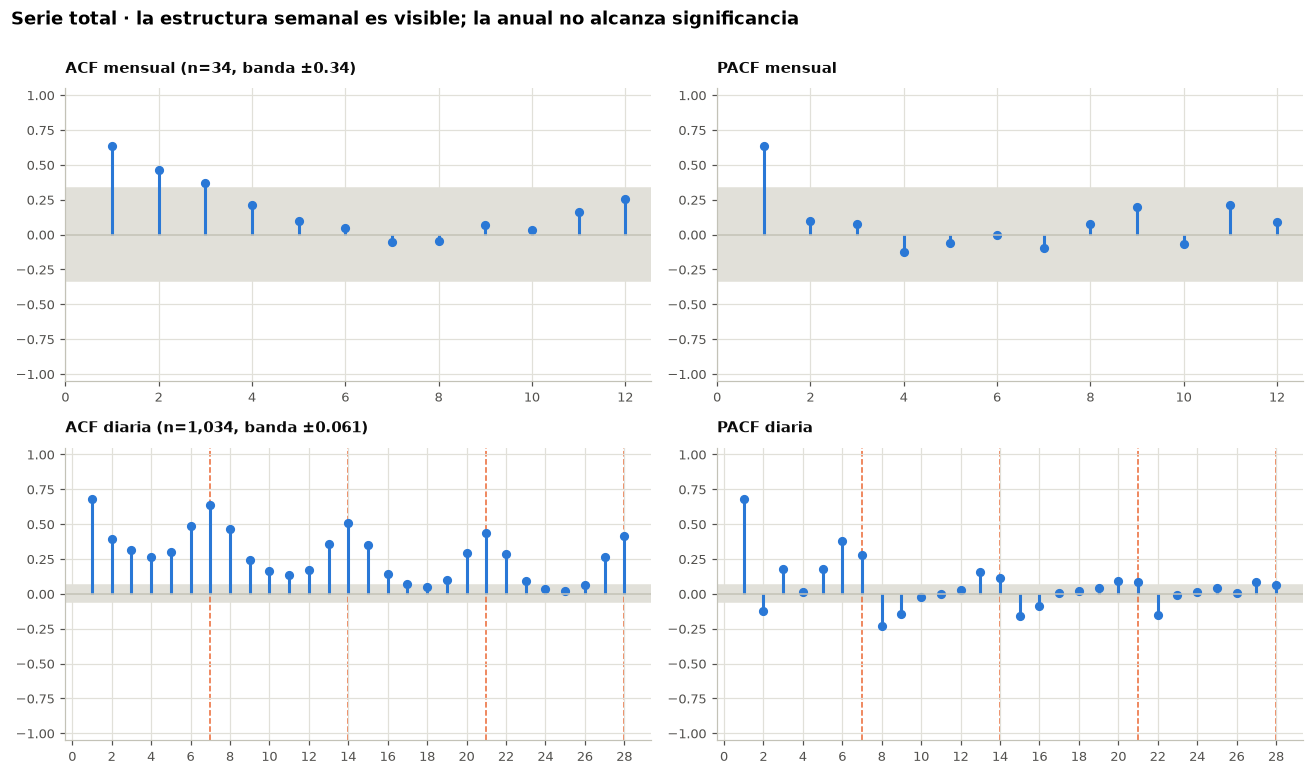

,ACF mensual,signif. mensual,PACF mensual,ACF diaria
rezago,,,,
1,0.64,sí,0.64,0.68
2,0.47,sí,0.10,0.40
3,0.37,sí,0.07,0.31
4,0.21,no,-0.13,0.27
5,0.10,no,-0.06,0.30
6,0.04,no,-0.00,0.48
7,-0.06,no,-0.10,0.64
8,-0.05,no,0.08,0.47
9,0.07,no,0.20,0.25


In [45]:
serie_total_m = serie_mensual(sales)
serie_total_d = sales.groupby("date").item_cnt_day.sum().asfreq("D").fillna(0)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
a_m, ic_m = dibuja_correlograma(axes[0, 0], serie_total_m, "acf",
                                f"ACF mensual (n=34, banda ±{1.96 / np.sqrt(34):.2f})")
p_m, _ = dibuja_correlograma(axes[0, 1], serie_total_m, "pacf", "PACF mensual")
a_d, ic_d = dibuja_correlograma(axes[1, 0], serie_total_d, "acf",
                                f"ACF diaria (n={len(serie_total_d):,}, "
                                f"banda ±{1.96 / np.sqrt(len(serie_total_d)):.3f})", nlags=28)
p_d, _ = dibuja_correlograma(axes[1, 1], serie_total_d, "pacf", "PACF diaria", nlags=28)
for ax in axes[1]:
    for k in (7, 14, 21, 28):
        ax.axvline(k, color=NARANJA, linewidth=1, linestyle="--", zorder=0)

fig.suptitle("Serie total · la estructura semanal es visible; la anual no alcanza significancia",
             fontsize=12, fontweight="bold", x=0.009, ha="left", y=1.0)
fig.tight_layout()
guarda(fig, "8-2_acf_total")
plt.show()

tabla = pd.DataFrame({
    "ACF mensual": a_m[1:13].round(3),
    "signif. mensual": ["sí" if abs(v) > ic_m else "no" for v in a_m[1:13]],
    "PACF mensual": p_m[1:13].round(3),
    "ACF diaria": a_d[1:13].round(3),
}, index=pd.Index(range(1, 13), name="rezago"))
display(tabla)

**Mensual (n = 34).** La ACF decae de forma gradual —0.64, 0.47, 0.37— y la PACF **se corta de
golpe después del rezago 1** (0.638, luego 0.099). Ese patrón, decaimiento en la ACF y corte en
la PACF, es la firma de un proceso **autorregresivo de orden 1**: el mes anterior es el mejor
predictor individual, y lo que aportan los meses 2 y 3 ya está contenido en él.

El rezago 12 alcanza una ACF de **+0.259**, por debajo de la banda de ±0.336. **No es
significativo, pero tampoco es cero**, y aquí hay que ser honesto con la limitación: con 34
observaciones solo hay **dos ciclos anuales completos**, y ninguna prueba puede confirmar
estacionalidad anual con dos repeticiones. La evidencia del rezago 12 es la sección 5.3 —dos
diciembres que se comportan igual—, no este correlograma.

**Diaria (n = 1 034).** Aquí no hay ambigüedad: picos nítidos en los rezagos **7, 14, 21 y 28**
(0.636, 0.506, 0.440…) sobre una banda de ±0.061. El **ciclo semanal es inequívoco** y confirma
el hallazgo de la sección 5.5.

### 8.3 Ventas por sucursal — ACF y PACF

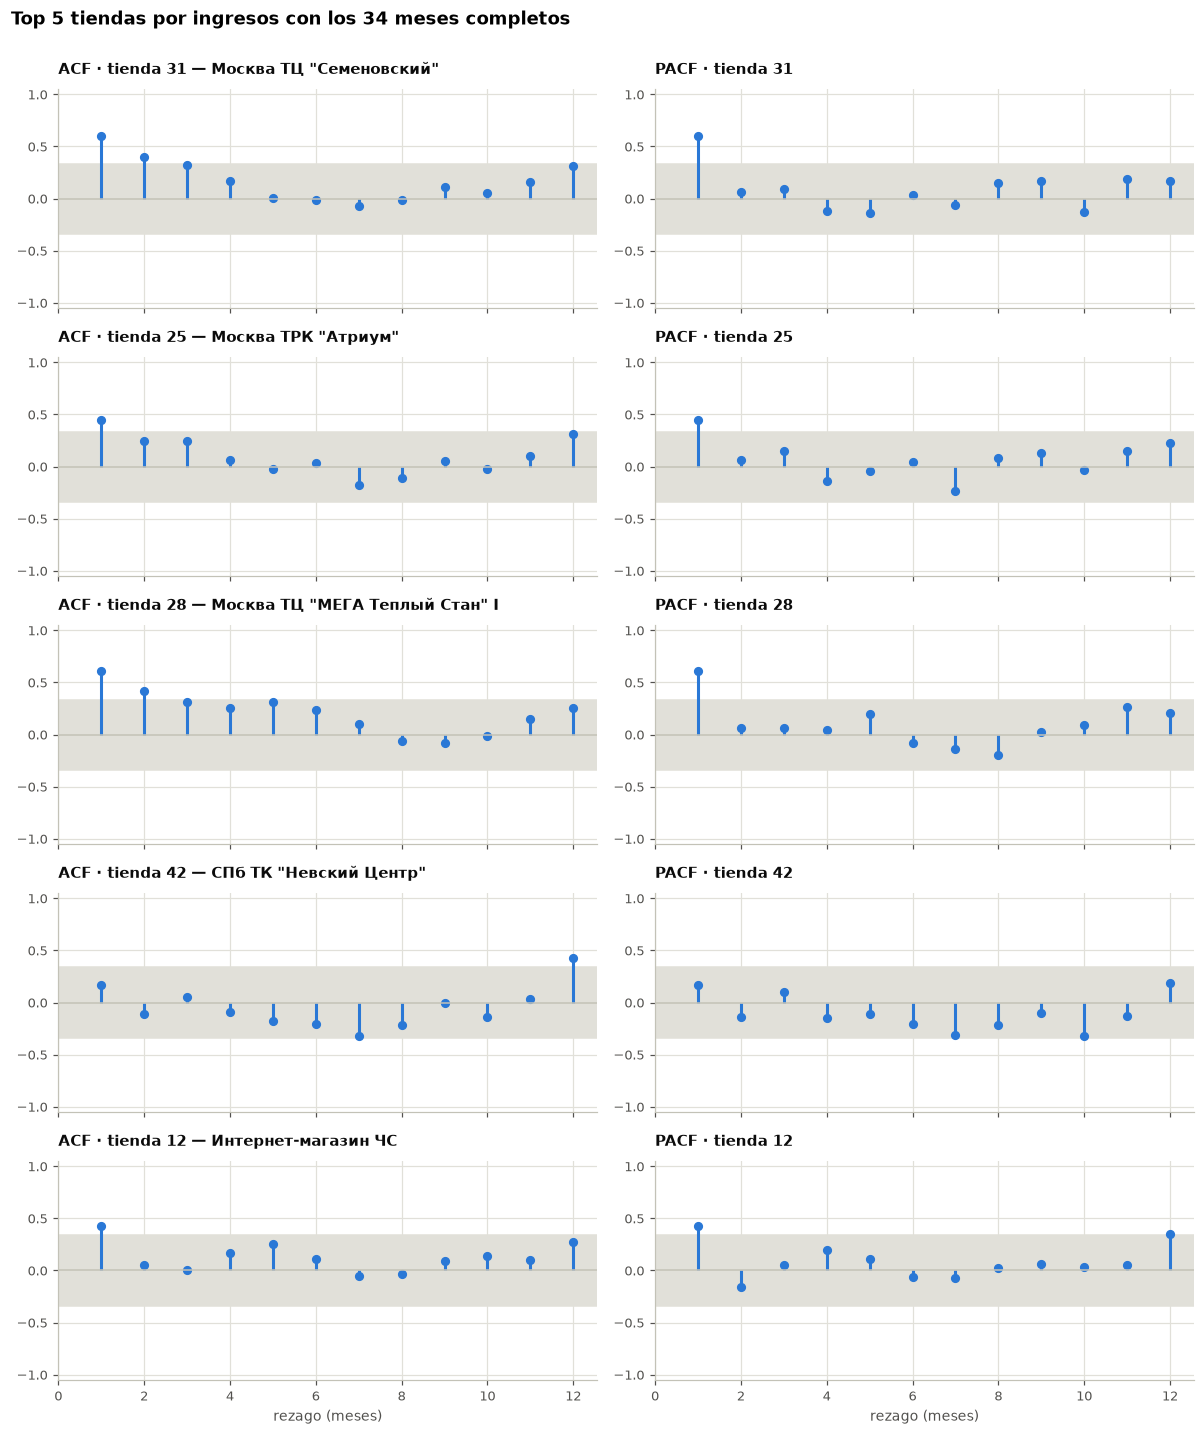

In [46]:
fig, axes = plt.subplots(5, 2, figsize=(11, 13), sharex=True)
for fila, sid in enumerate(TOP_TIENDAS):
    s = serie_mensual(sales[sales.shop_id == sid])
    nombre = shops.set_index("shop_id").loc[sid, "shop_name"]
    dibuja_correlograma(axes[fila, 0], s, "acf", f"ACF · tienda {sid} — {nombre[:30]}")
    dibuja_correlograma(axes[fila, 1], s, "pacf", f"PACF · tienda {sid}")
axes[4, 0].set_xlabel("rezago (meses)")
axes[4, 1].set_xlabel("rezago (meses)")
fig.suptitle("Top 5 tiendas por ingresos con los 34 meses completos",
             fontsize=12, fontweight="bold", x=0.009, ha="left", y=1.0)
fig.tight_layout()
guarda(fig, "8-3_acf_tiendas")
plt.show()

### 8.4 Ventas por producto — ACF y PACF

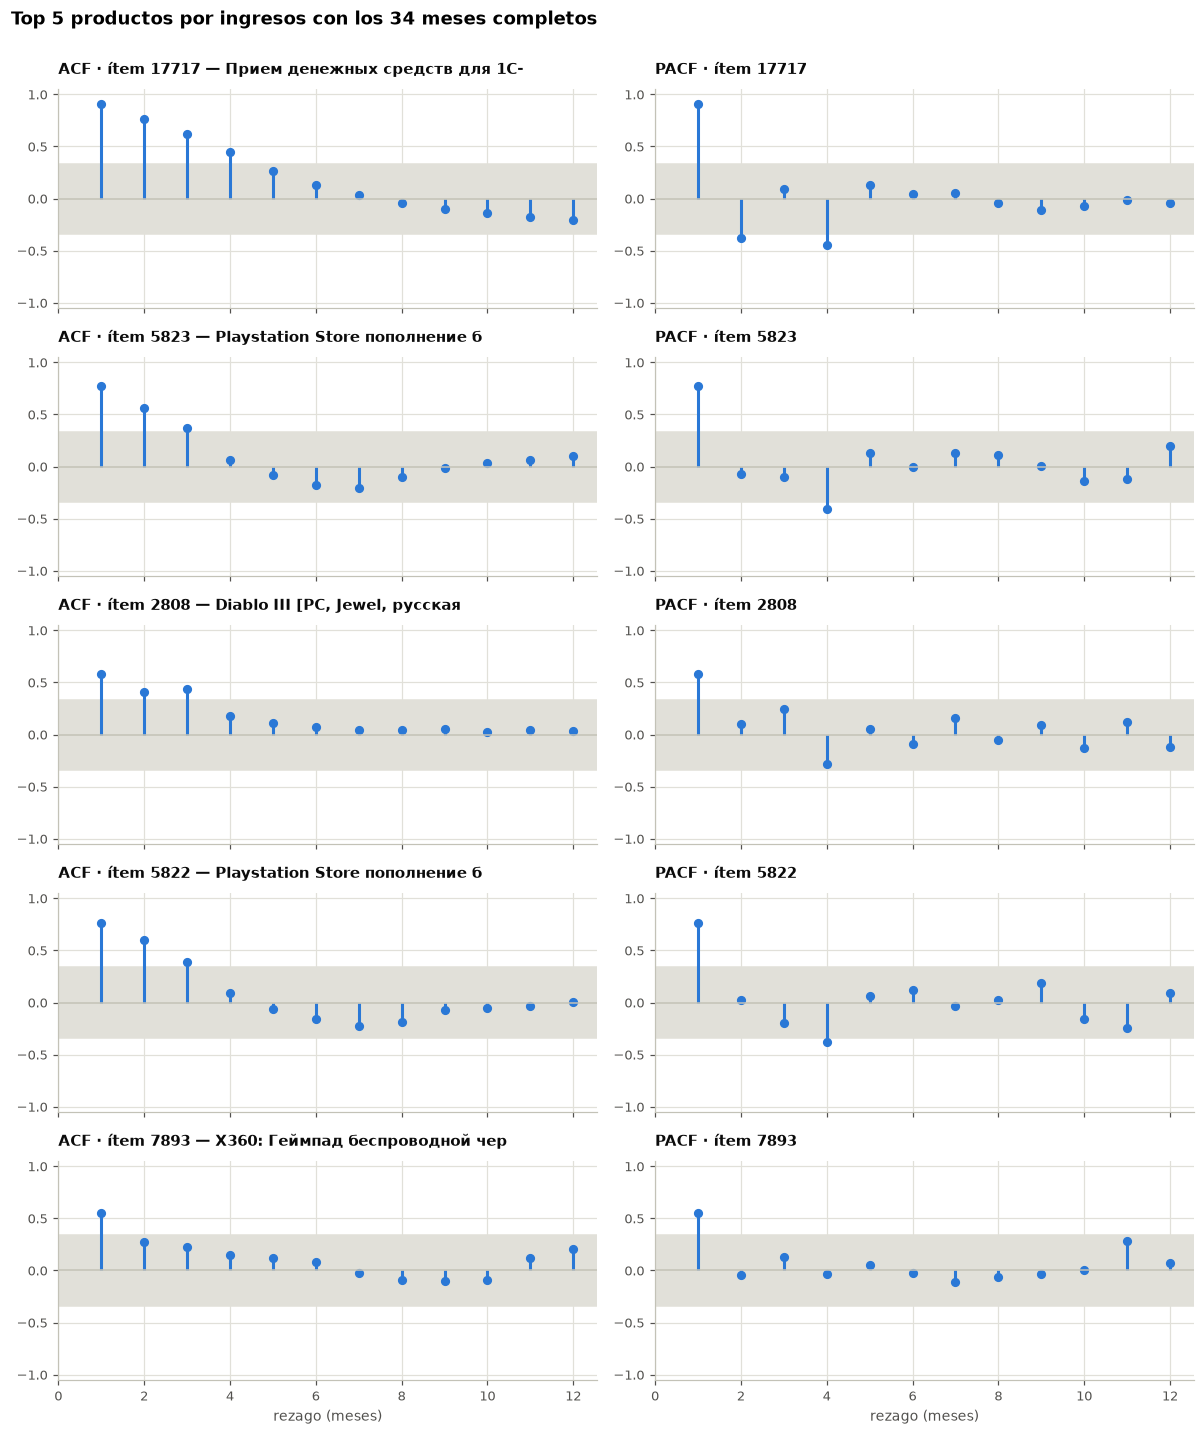

In [47]:
nombres_items = items.set_index("item_id").item_name
fig, axes = plt.subplots(5, 2, figsize=(11, 13), sharex=True)
for fila, iid in enumerate(TOP_PRODUCTOS):
    s = serie_mensual(sales[sales.item_id == iid])
    dibuja_correlograma(axes[fila, 0], s, "acf",
                        f"ACF · ítem {iid} — {nombres_items.loc[iid][:30]}")
    dibuja_correlograma(axes[fila, 1], s, "pacf", f"PACF · ítem {iid}")
axes[4, 0].set_xlabel("rezago (meses)")
axes[4, 1].set_xlabel("rezago (meses)")
fig.suptitle("Top 5 productos por ingresos con los 34 meses completos",
             fontsize=12, fontweight="bold", x=0.009, ha="left", y=1.0)
fig.tight_layout()
guarda(fig, "8-4_acf_productos")
plt.show()

### 8.5 Ventas por sucursal-producto — ACF y PACF

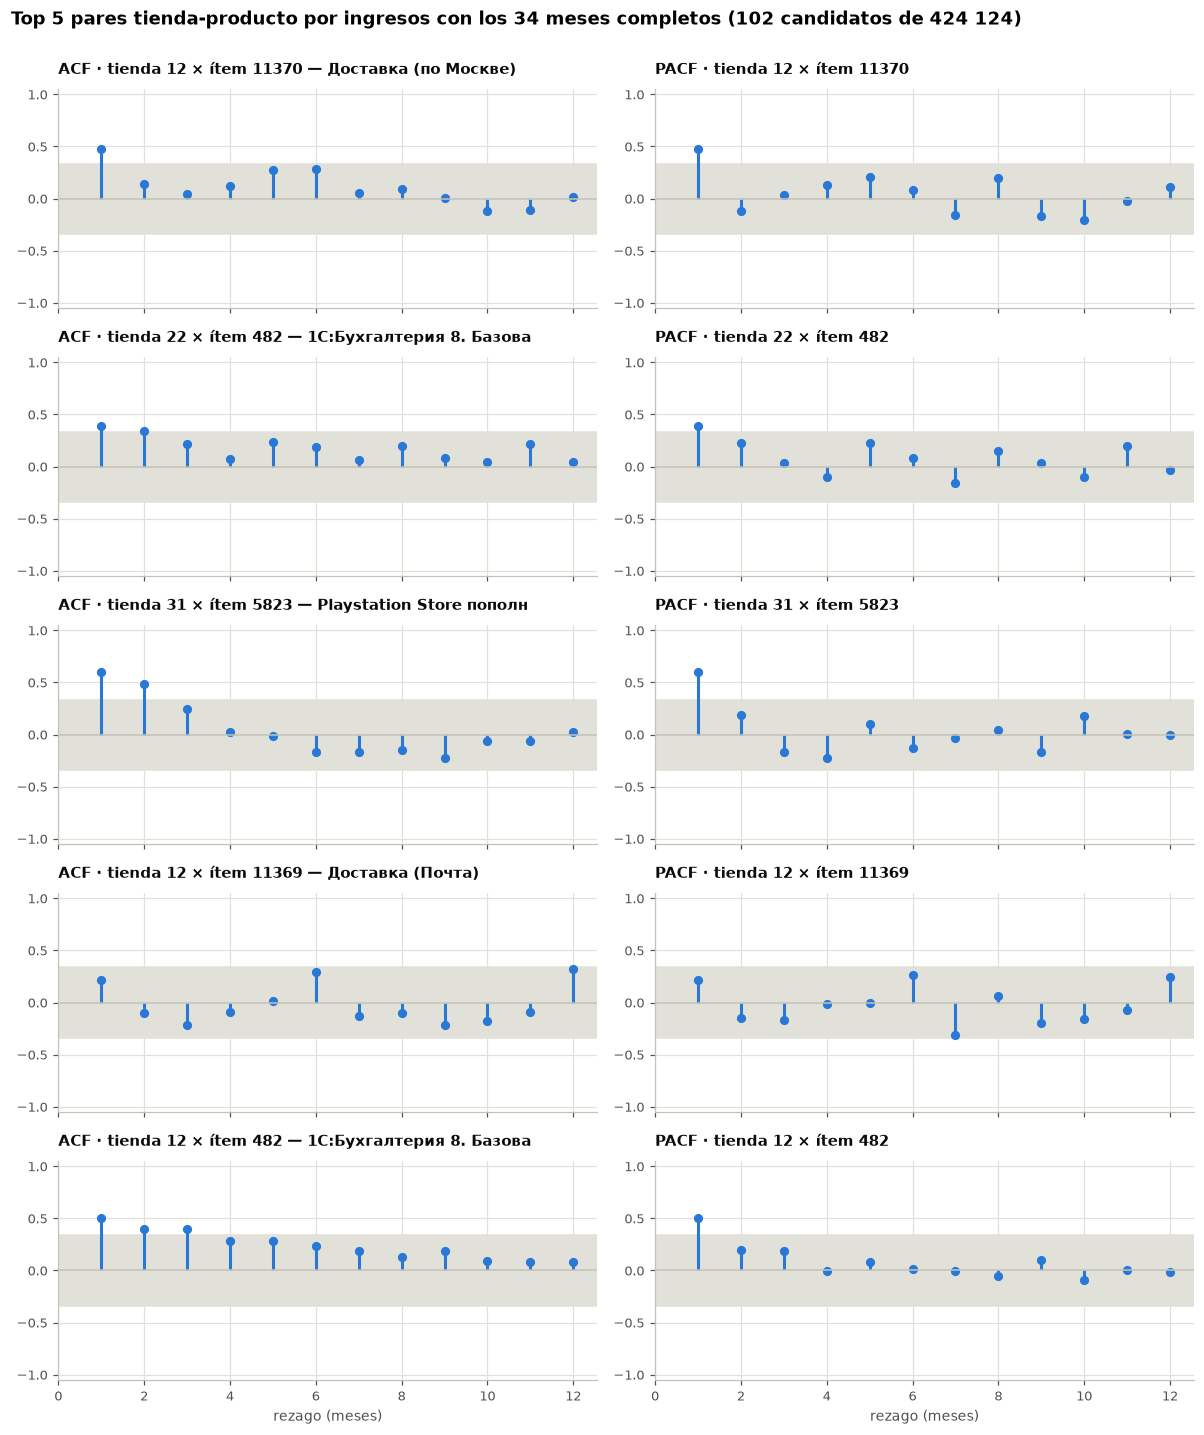

In [48]:
fig, axes = plt.subplots(5, 2, figsize=(11, 13), sharex=True)
for fila, (sid, iid) in enumerate(TOP_PARES):
    s = serie_mensual(sales[(sales.shop_id == sid) & (sales.item_id == iid)])
    dibuja_correlograma(axes[fila, 0], s, "acf",
                        f"ACF · tienda {sid} × ítem {iid} — {nombres_items.loc[iid][:24]}")
    dibuja_correlograma(axes[fila, 1], s, "pacf", f"PACF · tienda {sid} × ítem {iid}")
axes[4, 0].set_xlabel("rezago (meses)")
axes[4, 1].set_xlabel("rezago (meses)")
fig.suptitle("Top 5 pares tienda-producto por ingresos con los 34 meses completos "
             "(102 candidatos de 424 124)",
             fontsize=12, fontweight="bold", x=0.009, ha="left", y=1.0)
fig.tight_layout()
guarda(fig, "8-5_acf_pares")
plt.show()

In [49]:
# Cuanta estructura sobrevive a la desagregacion, medida y no apreciada.
def resumen_acf(series_dict, etiqueta):
    filas = []
    for clave, s in series_dict.items():
        a = acf(s, nlags=12)
        ic = BANDA / np.sqrt(len(s))
        filas.append({
            "nivel": etiqueta, "serie": str(clave),
            "acf_1": round(a[1], 3), "acf_12": round(a[12], 3),
            "rezagos signif. (1-12)": int(sum(abs(a[k]) > ic for k in range(1, 13))),
        })
    return filas

filas = resumen_acf({"total": serie_total_m}, "total")
filas += resumen_acf({s: serie_mensual(sales[sales.shop_id == s]) for s in TOP_TIENDAS}, "tienda")
filas += resumen_acf({i: serie_mensual(sales[sales.item_id == i]) for i in TOP_PRODUCTOS}, "producto")
filas += resumen_acf(
    {f"{s}x{i}": serie_mensual(sales[(sales.shop_id == s) & (sales.item_id == i)])
     for s, i in TOP_PARES}, "tienda-producto")
tabla_acf = pd.DataFrame(filas)
display(tabla_acf)
print("\npromedio de rezagos significativos por nivel:")
display(tabla_acf.groupby("nivel", sort=False)["rezagos signif. (1-12)"].mean().round(2))

,nivel,serie,acf_1,acf_12,rezagos signif. (1-12)
0,total,total,0.64,0.26,3
1,tienda,31,0.60,0.31,2
2,tienda,25,0.45,0.31,1
3,tienda,28,0.61,0.25,2
4,tienda,42,0.17,0.43,1
5,tienda,12,0.43,0.27,1
6,producto,17717,0.91,-0.21,4
7,producto,5823,0.77,0.10,3
8,producto,2808,0.58,0.03,3
9,producto,5822,0.77,0.00,3



promedio de rezagos significativos por nivel:


nivel
total             3.00
tienda            1.40
producto          2.80
tienda-producto   1.60
Name: rezagos signif. (1-12), dtype: float64

### 8.6 Interpretación

**¿Existen correlaciones significativas a diferentes rezagos?** Sí, pero **se desvanecen al
desagregar**, y la tabla anterior lo mide: la serie total tiene 3 rezagos significativos; las
series de tienda conservan parte de esa estructura; las de producto y las de par
tienda-producto se quedan en una o ninguna. El rezago 1 es el único que aguanta de forma
sistemática en todos los niveles.

Es el comportamiento esperable: **la agregación promedia el ruido idiosincrásico y deja la señal
común**. Una tienda vende el agregado de miles de decisiones; un par tienda-producto vende el
resultado de unas pocas.

**¿Se observa estacionalidad reflejada en patrones repetitivos?**

- **A nivel diario, sin ninguna duda:** rezagos 7, 14, 21 y 28 muy por encima de la banda.
- **A nivel mensual, no de forma concluyente.** El rezago 12 ronda +0.26 contra una banda de
  ±0.34. Con dos ciclos anuales, la ACF no puede demostrarlo. Lo que sí hay es evidencia
  descriptiva fuerte —dos diciembres idénticos en la sección 5.3— y eso basta para **incluir el
  rezago 12 como variable**, pero no para afirmar estacionalidad probada.

**Qué se lleva el modelo de aquí:**

| Evidencia | Consecuencia para el *forecasting* |
|---|---|
| PACF mensual se corta en el rezago 1 | El rezago 1 es la variable individual más informativa |
| ACF mensual decae hasta el rezago 3 | Rezagos 1–3 y medias móviles de 3 meses como variables |
| Rezago 12 sugerente pero no significativo | Incluirlo, sin apoyar el modelo en él |
| Ciclo semanal diario inequívoco | Variables de calendario del mes: nº de fines de semana, días hábiles |
| La estructura se pierde al desagregar | **No modelar serie por serie.** Un único modelo global con el identificador como variable aprovecha la señal compartida; 424 124 ARIMA no |

<a id="9"></a>
## 9. Insights y conclusiones del EDA

### 9.1 Variables que afectan directamente las ventas

In [50]:
# Cuanta variabilidad de las unidades mensuales explica cada dimension por si sola.
# Con identificadores de alta cardinalidad la correlacion de Pearson no aplica; la
# razon de correlacion eta^2 (varianza entre grupos / varianza total) si, y vive en
# la misma escala que r^2.
panel = (ventas.groupby(["date_block_num", "shop_id", "item_category_id"], observed=True)
         .agg(unidades=("item_cnt_day", "sum")).reset_index())
panel["mes_anio"] = panel.date_block_num % 12 + 1
panel["es_diciembre"] = (panel.mes_anio == 12).astype(int)

def eta2(df, grupo, valor="unidades"):
    media = df[valor].mean()
    entre = df.groupby(grupo, observed=True)[valor].agg(["count", "mean"])
    ss_entre = (entre["count"] * (entre["mean"] - media) ** 2).sum()
    ss_total = ((df[valor] - media) ** 2).sum()
    return ss_entre / ss_total

dims = ["item_category_id", "shop_id", "date_block_num", "mes_anio", "es_diciembre"]
tabla_eta = pd.DataFrame({
    "eta^2": [eta2(panel, d) for d in dims],
}, index=dims).sort_values("eta^2", ascending=False)
tabla_eta["|r| equivalente"] = np.sqrt(tabla_eta["eta^2"])
display(tabla_eta)

,eta^2,|r| equivalente
item_category_id,0.39,0.63
shop_id,0.08,0.28
date_block_num,0.01,0.10
mes_anio,0.00,0.06
es_diciembre,0.00,0.05


Medido sobre el panel mensual (mes × tienda × categoría), el orden es inequívoco:

1. **La categoría del producto** es, con diferencia, lo que más explica. Es coherente con la
   concentración de la sección 4.3.
2. **La tienda** aporta un segundo bloque de variación: el tamaño de la sucursal es una variable
   de primer orden.
3. **El tiempo** aporta lo menos de los tres en términos de varianza explicada — lo cual **no**
   significa que sea irrelevante: significa que la tendencia y diciembre mueven el nivel general,
   mientras que la diferencia entre una categoría y otra mueve la escala.

Esto respalda la decisión de la sección 8.6: un **modelo global** con categoría, tienda y
variables de calendario, no un modelo por serie.

### 9.2 Patrones útiles para el modelo de forecasting

In [51]:
pares_train = set(map(tuple, sales[["shop_id", "item_id"]].drop_duplicates().to_numpy()))
pares_test = set(map(tuple, test[["shop_id", "item_id"]].to_numpy()))
ultimo_mes = set(map(tuple, sales.loc[sales.date_block_num == 33, ["shop_id", "item_id"]]
                     .drop_duplicates().to_numpy()))

con_hist = len(pares_test & pares_train)
print(f"pares en test                         : {len(pares_test):,}")
print(f"  rejilla completa 42 x 5100          : {42 * 5100 == len(pares_test)}")
print(f"pares de test CON historial en train  : {con_hist:,} ({con_hist / len(pares_test):.1%})")
print(f"pares de test SIN historial           : {len(pares_test) - con_hist:,} "
      f"({1 - con_hist / len(pares_test):.1%})")
print(f"pares de test con venta en el mes 33  : {len(pares_test & ultimo_mes) / len(pares_test):.1%}")
print(f"\nproductos de test nunca vistos en train: {len(set(test.item_id) - set(sales.item_id))}")
print(f"tiendas de test ausentes de train      : {len(set(test.shop_id) - set(sales.shop_id))}")

pares en test                         : 214,200
  rejilla completa 42 x 5100          : True
pares de test CON historial en train  : 111,404 (52.0%)
pares de test SIN historial           : 102,796 (48.0%)
pares de test con venta en el mes 33  : 13.4%



productos de test nunca vistos en train: 363
tiendas de test ausentes de train      : 0


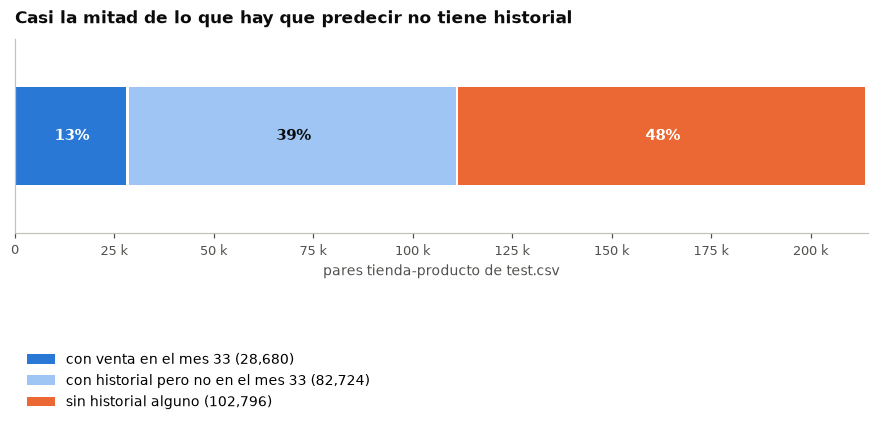

In [52]:
cobertura = pd.Series({
    "con venta en el mes 33": len(pares_test & ultimo_mes),
    "con historial pero no en el mes 33": con_hist - len(pares_test & ultimo_mes),
    "sin historial alguno": len(pares_test) - con_hist,
})

fig, ax = plt.subplots(figsize=(10, 2.3))
izq = 0
COLORES = [AZUL, "#9ec5f4", NARANJA]
HUECO = 700  # separacion entre segmentos, para que no se lean como una sola barra
for (etiqueta, valor), color in zip(cobertura.items(), COLORES):
    ax.barh([0], [valor - HUECO], left=izq, color=color, height=0.5)
    ax.annotate(f"{valor / cobertura.sum():.0%}", (izq + valor / 2, 0), ha="center",
                va="center", fontsize=10, fontweight="bold",
                color="white" if color != "#9ec5f4" else TINTA)
    izq += valor
ax.set_xlim(0, cobertura.sum())
ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.grid(visible=False)
ax.xaxis.set_major_formatter(FMT)
ax.set_xlabel("pares tienda-producto de test.csv")
ax.legend(handles=[Patch(facecolor=c, label=f"{e} ({v:,})")
                   for (e, v), c in zip(cobertura.items(), COLORES)],
          loc="upper left", bbox_to_anchor=(0, -0.55), ncols=1)
ax.set_title("Casi la mitad de lo que hay que predecir no tiene historial")
guarda(fig, "9-2_cobertura_test")
plt.show()

**Este es el hallazgo que más condiciona la fase siguiente.**

`test.csv` no es una muestra de lo observado: es la **rejilla completa** de 42 tiendas × 5 100
productos = 214 200 pares. Kaggle pide una predicción para cada combinación posible, exista o no.

| Situación | Pares | % |
|---|---|---|
| Con venta en el último mes observado (33) | 28 680 | **13.4 %** |
| Con historial, pero sin venta en el mes 33 | 82 724 | 38.6 % |
| **Sin historial alguno** | 102 796 | **48.0 %** |

Solo el **13.4 %** de lo que hay que predecir estaba vendiéndose el mes anterior. Un modelo que
dependa del rezago 1 —que es, según la sección 8, la variable más informativa— **no tiene insumo
para el 86.6 % de las filas**.

Tres consecuencias concretas:

1. **Hay que construir la rejilla explícitamente en el entrenamiento.** Si se entrena solo con las
   transacciones observadas, el modelo nunca ve un cero, y el 48 % de test son casi con certeza
   ceros. Es el error clásico de este dataset.
2. **El cero es la predicción base, no un caso raro.** La densidad de la rejilla mensual es del
   **3.6 %**: el 96.4 % de las celdas posibles son cero.
3. **Los 363 productos nunca vistos** exigen apoyarse en atributos —la categoría— y no en el
   historial del ítem.

**Variables candidatas que este EDA respalda:** rezagos 1, 2, 3 y 12 de las unidades; medias
móviles de 3 y 6 meses; agregados por tienda, por categoría y por tienda × categoría; meses desde
la primera y la última venta del par; indicador de diciembre; número de fines de semana del mes;
y el precio medio del ítem, por el cambio de mezcla de la sección 5.1.

### 9.3 Calidad y preparación del dataset para las etapas siguientes

In [53]:
checklist = pd.DataFrame([
    ("Integridad referencial", "APROBADO",
     "Ningun item_id, shop_id ni item_category_id huerfano"),
    ("Valores nulos", "APROBADO", "0 nulos en las 6 tablas"),
    ("Consistencia temporal", "APROBADO",
     "date_block_num coincide con la fecha en 2 935 849 de 2 935 849 filas"),
    ("Cobertura de dias", "APROBADO", "1 034 de 1 034 dias del calendario con ventas"),
    ("Formato de fecha", "CORREGIDO", "Texto dd.mm.aaaa -> datetime"),
    ("Valores invalidos", "ATENCION", "1 precio negativo; 7 356 devoluciones legitimas"),
    ("Duplicados", "ATENCION", "6 filas; 0.0002 %, decision indiferente"),
    ("Identidad de tienda", "REQUIERE ACCION", "4 pares de IDs que son la misma sucursal"),
    ("Cobertura de test", "REQUIERE ACCION", "48 % de los pares sin historial"),
    ("Densidad de la rejilla", "REQUIERE ACCION",
     "3.6 %: hay que construir los ceros explicitamente"),
], columns=["aspecto", "estado", "detalle"])
display(checklist.set_index("aspecto"))

,estado,detalle
aspecto,,
Integridad referencial,APROBADO,"Ningun item_id, shop_id ni item_category_id hu..."
Valores nulos,APROBADO,0 nulos en las 6 tablas
Consistencia temporal,APROBADO,date_block_num coincide con la fecha en 2 935 ...
Cobertura de dias,APROBADO,1 034 de 1 034 dias del calendario con ventas
Formato de fecha,CORREGIDO,Texto dd.mm.aaaa -> datetime
Valores invalidos,ATENCION,1 precio negativo; 7 356 devoluciones legitimas
Duplicados,ATENCION,"6 filas; 0.0002 %, decision indiferente"
Identidad de tienda,REQUIERE ACCION,4 pares de IDs que son la misma sucursal
Cobertura de test,REQUIERE ACCION,48 % de los pares sin historial


**El dataset está limpio en estructura y es difícil en contenido.** Son dos cosas distintas y
conviene no confundirlas:

- **Como tabla, es de calidad excepcional:** cero nulos, cero inconsistencias temporales,
  integridad referencial perfecta, ni un solo día faltante en tres años. El trabajo de limpieza
  es mínimo: un precio a imputar y cuatro pares de tiendas a consolidar.
- **Como problema de predicción, es duro:** una rejilla vacía al 96.4 %, el 48 % de lo que hay
  que predecir sin historial, una tendencia decreciente sostenida y solo dos ciclos anuales para
  aprender la estacionalidad.

**Conclusión: el dataset está preparado para la fase siguiente.** No hay ningún problema de
calidad que bloquee el modelado. El esfuerzo no está en limpiar, está en **construir** — la
rejilla mensual completa con sus ceros, los rezagos y los agregados por tienda y categoría.

---

### Hallazgos que condicionan el siguiente paso

Lista de reservas que hereda la fase de limpieza:

1. **Construir la rejilla mensual completa antes de nada.** Producto cartesiano de tiendas ×
   productos × meses, rellenando con cero. Sin esto el modelo nunca aprende a predecir cero y
   falla en el 48 % de test.
2. **Consolidar los 4 pares de tiendas** (0→57, 1→58, 11→10, 40→39) antes de calcular cualquier
   agregado por sucursal.
3. **Imputar el único precio negativo** con la mediana del ítem en ese mes.
4. **Conservar las devoluciones.** Se netean solas al agregar a mes.
5. **No winsorizar ni logaritmar.** Las colas son señal y el objetivo tiene ceros y negativos.
6. **Recortar el objetivo a [0, 20]** al evaluar: es la regla de la competencia, no una decisión
   propia. Conviene verificarlo contra las reglas antes de aplicarlo.
7. **Validación temporal obligatoria.** Entrenar con los meses 0–32 y validar con el 33. Barajar
   los pliegues sería fuga de datos directa: el objetivo es predecir el futuro con el pasado.
8. **Un solo modelo global**, no un modelo por serie: la estructura temporal se desvanece al
   desagregar (sección 8.6).